# BÁO CÁO CUỐI KỲ — ADY201m
## Phân loại nhãn tiền tiểu đường/tiểu đường trong khảo sát BRFSS2015 ở người từ 60 tuổi trở lên
**Nhóm 6 — AI2104**

| Thành viên | Mã sinh viên |
|---|---|
| Trần Tuấn Hiệp | HE211144 |
| Nguyễn Thế Hải | HE211655 |
| Trần Công Du | HE211007 |

Báo cáo kết nối xác định vấn đề, dữ liệu thô, tiền xử lý, SQL, phân tích và trực quan Python, so sánh Logistic Regression cùng các mô hình cây. Nhãn 1 gồm tiền tiểu đường/tiểu đường tự khai; kết quả mô tả mẫu khảo sát, không phải dự báo phát bệnh tương lai.

**Cách đọc:** phần I–III trình bày vấn đề, dữ liệu và tiền xử lý; phần IV trình bày EDA trên toàn bộ dữ liệu sạch (N = 143,454); phần V thiết kế biến tương tác và kiểm định VIF; phần VI phân chia Train/Test và so sánh mô hình qua 5-Fold CV trên Train. Phần VII đánh giá cuối trên Test độc lập; phần VIII kết luận, nêu giới hạn và giả thuyết nghiên cứu tiếp theo. Nhóm dừng dự án ở phần VIII.

**Trạng thái biên tập:** Nhóm đã chạy EDA trên toàn bộ tập sạch, kiểm định VIF, 5-Fold CV so sánh 20/16 biến và các lượt thử tương tác. Nhóm đã chốt Logistic Regression và XGBoost, đánh giá cuối trên Test độc lập tại phần VII. Nhóm đã rà soát sự nhất quán giữa mục tiêu, phương pháp, số liệu và kết luận; nhóm giữ nguyên mô hình và dự đoán đã lưu.

# I. Vấn đề và phương pháp nghiên cứu


#### BUSINESS CONTEXT & PROJECT JUSTIFICATION

**Bối cảnh:** Nhóm hướng đến tình huống người từ 60 tuổi trở lên muốn được đánh giá ban đầu về tình trạng tiền tiểu đường/tiểu đường trong thời gian chờ kết quả xét nghiệm. Nhóm tìm hiểu khả năng sử dụng học máy để khai thác các thông tin sức khỏe, hành vi và nhân khẩu học mà người tham gia cung cấp trong khảo sát. Qua nghiên cứu này, nhóm muốn đánh giá tiềm năng hỗ trợ nhân viên y tế tham khảo thông tin trước khi đưa ra quyết định chuyên môn.

**Vấn đề nghiên cứu:** Nhóm nghiên cứu khả năng của các mô hình học máy truyền thống trong việc phân loại nhãn gộp tiền tiểu đường/tiểu đường ở người từ 60 tuổi trở lên dựa trên các đặc điểm khảo sát. Nhóm so sánh kết quả giữa các mô hình để đánh giá khả năng nhận diện trường hợp mang nhãn dương và mức độ phân loại sai.

**Lý do chọn nhóm tuổi từ 60 trở lên:** Nhóm lựa chọn người từ 60 tuổi trở lên vì nguy cơ mắc tiểu đường tăng theo tuổi, nên đây là nhóm có nguy cơ cao hơn và cần được hỗ trợ đánh giá ban đầu [nguồn nhóm bổ sung]. Nhóm giới hạn phạm vi tuổi để tìm hiểu khả năng phân loại nhãn khảo sát trong nhóm đối tượng này. Nhóm không diễn giải mối liên hệ với tuổi như quan hệ nhân quả và không suy ra tỷ lệ bệnh trong dân số từ mẫu khảo sát.

**Đối tượng sử dụng và quyết định hỗ trợ:** Nhóm xác định người từ 60 tuổi trở lên là đối tượng hưởng lợi dự kiến và nhân viên y tế là người sử dụng kết quả tham khảo. Trong phạm vi đề tài, nhóm đánh giá mô hình trên dữ liệu khảo sát. Nhân viên y tế giữ quyền quyết định về xét nghiệm, chẩn đoán và chăm sóc người bệnh.

**Phạm vi và giới hạn:** Nhóm giữ nhãn gộp hiện tại: lớp 1 gồm tiền tiểu đường và tiểu đường tự khai (DIABETE3=1 hoặc 4); lớp 0 gồm người trả lời không mắc tiểu đường (DIABETE3=3). Nhóm loại hồ sơ chỉ tiểu đường khi mang thai (DIABETE3=2). Nhóm đánh giá khả năng phân loại nhãn khảo sát trong mẫu sau làm sạch; nhóm không sử dụng kết quả để khẳng định khả năng dự đoán phát bệnh trong tương lai hoặc quan hệ nhân quả.


#### CORE RESEARCH QUESTIONS

1. **Trong mẫu người từ 60 tuổi trở lên, nhóm quan sát thấy những đặc điểm sức khỏe, hành vi và nhân khẩu học nào có liên quan đến nhãn gộp tiền tiểu đường/tiểu đường?**

2. **Nhóm đạt được mức Average Precision (AP), Accuracy, Precision, Recall và F1-score nào khi sử dụng các mô hình học máy truyền thống để phân loại nhãn gộp này từ các đặc điểm khảo sát?**

3. **Khi so sánh các mô hình, nhóm ghi nhận sự đánh đổi giữa khả năng nhận diện lớp 1 và mức báo nhầm ra sao?**

Nhóm sử dụng SQL để kiểm tra và chuẩn bị dữ liệu; nhóm sử dụng pandas/NumPy để phân tích các câu hỏi nghiên cứu và tổng hợp kết quả mô hình trong các phần sau.


#### DATA SCIENCE PROBLEM FORMULATION

- **Loại bài toán:** Nhóm thực hiện bài toán học có giám sát, phân loại nhị phân trong phạm vi nghiên cứu học thuật.
- **Đơn vị phân tích:** Nhóm phân tích từng bản ghi khảo sát của người từ 60 tuổi trở lên sau khi áp dụng các điều kiện chọn mẫu và làm sạch dữ liệu.
- **Biến mục tiêu:** Nhóm sử dụng `Diabetes_binary`, gán lớp 0 cho `DIABETE3=3` và lớp 1 cho `DIABETE3=1` hoặc `4`. Nhóm loại hồ sơ chỉ tiểu đường khi mang thai (`DIABETE3=2`) và trình bày cách xử lý nhãn thiếu hoặc mã phản hồi không hợp lệ ở phần tiền xử lý.
- **Đầu vào:** Nhóm sử dụng 20 đặc điểm sức khỏe, hành vi và nhân khẩu học làm bộ ứng viên ban đầu. Nhóm sẽ trình bày các bộ đặc trưng dùng trong thử nghiệm tại phần lựa chọn đặc trưng.
- **Đầu ra:** Với mỗi bản ghi, nhóm sử dụng mô hình để phân loại vào lớp 0 hoặc lớp 1 theo định nghĩa nhãn gộp.
- **Đánh giá:** Nhóm chọn mô hình và biến theo AP trung bình qua 5 fold trên Train, dùng chung fold giữa các phương án. Sau khi chốt, nhóm đánh giá hai mô hình cuối trên Test bằng AP, ROC AUC, Accuracy, Precision, Recall và F1-score; nhóm lấy lớp 1 làm lớp dương. Nhóm sử dụng ma trận nhầm lẫn để phân tích số trường hợp bỏ sót và báo nhầm. Nhóm giữ ngưỡng phân loại 0,5 trong các thử nghiệm.
- **Phạm vi diễn giải:** Nhóm đánh giá khả năng phân loại nhãn tự khai trong mẫu khảo sát sau làm sạch. Nhóm chưa kiểm chứng khả năng ứng dụng tại bệnh viện hoặc dự báo phát bệnh trong tương lai.


# II. Nguồn dữ liệu và khám phá ban đầu

### DATA SOURCE & COLLECTION METHOD

Nhóm sử dụng `data.csv` làm đầu vào của báo cáo. Nhóm tạo tệp này từ `data_đầu_vào/2015.csv` bằng cách chọn `_AGEG5YR` mã 9–13, gồm người từ 60 tuổi trở lên. Nhóm giữ 202,412 hồ sơ và 330 cột nguồn, giữ nguyên thứ tự hồ sơ, giá trị thiếu và mã khảo sát. Nhóm chưa làm sạch, loại nhãn hoặc xóa hồ sơ trùng khi tạo tệp.

Nhóm sử dụng dữ liệu khảo sát BRFSS2015 do CDC công bố và tham khảo bộ biến của Alex Teboul để chọn 20 đặc trưng ứng viên cùng một biến mục tiêu. Nhóm sẽ loại `DIABETE3=2`, xử lý mã phản hồi và tạo nhãn gộp tiền tiểu đường/tiểu đường trong phần tiền xử lý.

Nhóm đọc trực tiếp `data.csv` bằng pandas khi chạy báo cáo. Nhóm không cần giải nén ZIP hoặc đọc XPT. Nhóm tính số hồ sơ trước và sau làm sạch từ đầu vào đã chọn tuổi này.

**Nguồn:** [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html), [codebook, trang 112](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf), [bộ biến tham khảo](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset).


In [60]:
# Khởi tạo môi trường thư viện và CSDL SQLite cho môn học ADY201m
import os
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Cấu hình hiển thị bảng đầy đủ, không bị cắt bớt bằng dấu 3 chấm (...)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', None)

# 1. Khởi tạo CSDL SQLite trong bộ nhớ (In-memory SQLite Database)
conn = sqlite3.connect(':memory:')

# 2. Đăng ký hàm %%sql ngắn gọn, dễ hiểu cho sinh viên năm nhất
def sql_magic(line, cell):
    query = cell.strip()
    first_word = query.split()[0].upper() if query.split() else ''
    if first_word in ['CREATE', 'DROP', 'INSERT', 'UPDATE', 'ALTER']:
        conn.executescript(query)
        conn.commit()
        print('✓ Thực thi câu lệnh SQL thành công!')
    else:
        return pd.read_sql_query(query, conn)

try:
    get_ipython().register_magic_function(sql_magic, 'cell', 'sql')
    print('✓ Đã kích hoạt thành công cú pháp SQL Magic (%%sql) cho Notebook.')
except Exception:
    pass

# 3. Đọc dữ liệu khảo sát gốc BRFSS 2015 và nạp vào bảng SQLite `raw_data`
SOURCE_COLS = [
    'DIABETE3', '_RFHYPE5', 'TOLDHI2', '_CHOLCHK', '_BMI5', 'SMOKE100', 'CVDSTRK3', '_MICHD',
    '_TOTINDA', '_FRTLT1', '_VEGLT1', '_RFDRHV5', 'HLTHPLN1', 'MEDCOST', 'GENHLTH', 'MENTHLTH',
    'PHYSHLTH', 'DIFFWALK', 'SEX', '_AGEG5YR', 'EDUCA'
]

csv_file = '2015.csv' if os.path.exists('2015.csv') else 'data.csv'
df_raw = pd.read_csv(csv_file, float_precision='round_trip')
print(f"Kích thước tệp dữ liệu thô: {df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")

# Lọc phạm vi người cao tuổi (≥60 tuổi) và nạp vào bảng SQLite raw_data
df_scope = df_raw[df_raw['_AGEG5YR'].isin([9, 10, 11, 12, 13]) & (df_raw['DIABETE3'] != 2)][SOURCE_COLS].copy()
df_scope.to_sql('raw_data', conn, index=False, if_exists='replace')
print(f"✓ Đã nạp {len(df_scope):,} hồ sơ người cao tuổi vào bảng SQLite `raw_data` sẵn sàng làm sạch!")

# 4. Kiểm tra cấu trúc, số ô non-null và bộ nhớ bằng .info()
print('\n' + '='*70)
print('THÔNG TIN CẤU TRÚC VÀ BỘ NHỚ CỦA TẬP DỮ LIỆU THÔ (df_scope.info()):')
print('='*70)
df_scope.info()


✓ Đã kích hoạt thành công cú pháp SQL Magic (%%sql) cho Notebook.
Kích thước tệp dữ liệu thô: 441,456 dòng × 330 cột
✓ Đã nạp 201,596 hồ sơ người cao tuổi vào bảng SQLite `raw_data` sẵn sàng làm sạch!

THÔNG TIN CẤU TRÚC VÀ BỘ NHỚ CỦA TẬP DỮ LIỆU THÔ (df_scope.info()):
<class 'pandas.DataFrame'>
Index: 201596 entries, 0 to 441455
Data columns (total 21 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   DIABETE3  201591 non-null  float64
 1   _RFHYPE5  201596 non-null  float64
 2   TOLDHI2   192184 non-null  float64
 3   _CHOLCHK  201596 non-null  float64
 4   _BMI5     187939 non-null  float64
 5   SMOKE100  195864 non-null  float64
 6   CVDSTRK3  201596 non-null  float64
 7   _MICHD    199064 non-null  float64
 8   _TOTINDA  201596 non-null  float64
 9   _FRTLT1   201596 non-null  float64
 10  _VEGLT1   201596 non-null  float64
 11  _RFDRHV5  201596 non-null  float64
 12  HLTHPLN1  201596 non-null  float64
 13  MEDCOST   201595 non-null  flo

In [61]:
%%sql
-- Bảng 1: Hiển thị 5 dòng đầu tiên của dữ liệu thô từ bảng SQLite raw_data
SELECT DIABETE3, _RFHYPE5, TOLDHI2, _CHOLCHK, _BMI5, SMOKE100, GENHLTH, _AGEG5YR, SEX
FROM raw_data
LIMIT 5;


Out[0]: 
   DIABETE3  _RFHYPE5  TOLDHI2  _CHOLCHK   _BMI5  SMOKE100  GENHLTH  _AGEG5YR  SEX
0       3.0       2.0      1.0       1.0  4018.0       1.0      5.0       9.0  2.0
1       3.0       1.0      1.0       1.0  2204.0       NaN      4.0      11.0  2.0
2       3.0       2.0      1.0       1.0  2819.0       2.0      5.0       9.0  2.0
3       3.0       1.0      2.0       1.0  2437.0       2.0      5.0       9.0  2.0
4       3.0       2.0      2.0       1.0  2652.0       2.0      2.0      11.0  2.0


DIABETE3,_RFHYPE5,TOLDHI2,_CHOLCHK,_BMI5,SMOKE100,GENHLTH,_AGEG5YR,SEX
3.0,2.0,1.0,1.0,4018.0,1.0,5.0,9.0,2.0
3.0,1.0,1.0,1.0,2204.0,NaN,4.0,11.0,2.0
3.0,2.0,1.0,1.0,2819.0,2.0,5.0,9.0,2.0
3.0,1.0,2.0,1.0,2437.0,2.0,5.0,9.0,2.0
3.0,2.0,2.0,1.0,2652.0,2.0,2.0,11.0,2.0


In [62]:
%%sql
-- Bảng 2: Thông tin tổng quan tệp khảo sát BRFSS 2015 trong SQLite
SELECT 
    COUNT(*) AS Tong_so_ho_so_nguoi_cao_tuoi,
    21 AS So_bien_nghien_cuu_chinh,
    'Khảo sát hành vi sức khỏe BRFSS 2015 (CDC Hoa Kỳ)' AS Nguon_du_lieu,
    'SQLite (In-Memory Database)' AS He_quan_tri_CSDL
FROM raw_data;


Out[0]: 
   Tong_so_ho_so_nguoi_cao_tuoi  So_bien_nghien_cuu_chinh                                      Nguon_du_lieu             He_quan_tri_CSDL
0                        201596                        21  Khảo sát hành vi sức khỏe BRFSS 2015 (CDC Hoa Kỳ)  SQLite (In-Memory Database)


Tong_so_ho_so_nguoi_cao_tuoi,So_bien_nghien_cuu_chinh,Nguon_du_lieu,He_quan_tri_CSDL
201596,21,Khảo sát hành vi sức khỏe BRFSS 2015 (CDC Hoa Kỳ),SQLite (In-Memory Database)


In [63]:
%%sql
-- Bảng 3: Cơ cấu phân bố người cao tuổi theo nhóm tuổi trong dữ liệu thô (≥60 tuổi)
SELECT 
    _AGEG5YR AS Ma_nhom_tuoi,
    CASE _AGEG5YR
        WHEN 9 THEN '60–64 tuổi'
        WHEN 10 THEN '65–69 tuổi'
        WHEN 11 THEN '70–74 tuổi'
        WHEN 12 THEN '75–79 tuổi'
        WHEN 13 THEN '≥80 tuổi'
    END AS Khoang_tuoi,
    COUNT(*) AS So_nguoi,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM raw_data), 2) AS Ty_le_pt
FROM raw_data
GROUP BY _AGEG5YR
ORDER BY _AGEG5YR;


Out[0]: 
   Ma_nhom_tuoi Khoang_tuoi  So_nguoi  Ty_le_pt
0           9.0  60–64 tuổi     49566     24.59
1          10.0  65–69 tuổi     49075     24.34
2          11.0  70–74 tuổi     38226     18.96
3          12.0  75–79 tuổi     28128     13.95
4          13.0    ≥80 tuổi     36601     18.16


Ma_nhom_tuoi,Khoang_tuoi,So_nguoi,Ty_le_pt
9.0,60–64 tuổi,49566,24.59
10.0,65–69 tuổi,49075,24.34
11.0,70–74 tuổi,38226,18.96
12.0,75–79 tuổi,28128,13.95
13.0,≥80 tuổi,36601,18.16


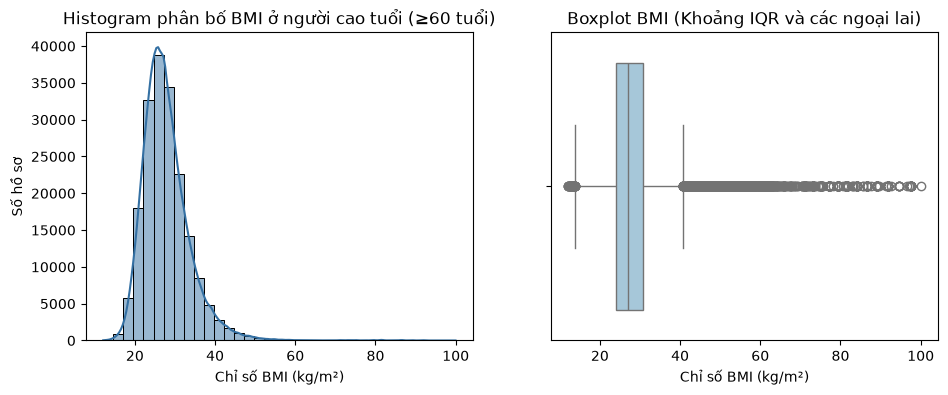

In [64]:
# Biểu đồ 1: Phân bố BMI thô trước làm sạch và thống kê khoảng IQR
# Chỉ số BMI trong BRFSS được lưu dưới dạng _BMI5 nhân 100
bmi_raw = (df_scope['_BMI5'].dropna() / 100.0).round(2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(bmi_raw, bins=35, color='#3470a3', kde=True, ax=ax1)
ax1.set_title("Histogram phân bố BMI ở người cao tuổi (≥60 tuổi)")
ax1.set_xlabel("Chỉ số BMI (kg/m²)")
ax1.set_ylabel("Số hồ sơ")

sns.boxplot(x=bmi_raw, color='#9ecae1', ax=ax2)
ax2.set_title("Boxplot BMI (Khoảng IQR và các ngoại lai)")
ax2.set_xlabel("Chỉ số BMI (kg/m²)")
plt.show()


In [65]:
# Bảng 4: Chất lượng 20 biến ứng viên và nhãn mục tiêu trước làm sạch
# Đếm số ô khuyết (NaN) và các mã khảo sát không biết/từ chối (7, 9, 77, 99, 9999)
records_qual = []
for col in SOURCE_COLS:
    n_nan = df_scope[col].isna().sum()
    n_spec = df_scope[col].isin([7, 9, 77, 99, 9999]).sum()
    records_qual.append({
        "Biến": col,
        "Số ô NaN": n_nan,
        "Tỷ lệ NaN (%)": round(n_nan / len(df_scope) * 100, 2),
        "Số mã đặc biệt": n_spec,
        "Tỷ lệ đặc biệt (%)": round(n_spec / len(df_scope) * 100, 2)
    })
df_qual = pd.DataFrame(records_qual).sort_values(by="Số ô NaN", ascending=False)
display(df_qual)


,Biến,Số ô NaN,Tỷ lệ NaN (%),Số mã đặc biệt,Tỷ lệ đặc biệt (%)
4,_BMI5,13657,6.77,0,0.00
2,TOLDHI2,9412,4.67,2154,1.07
5,SMOKE100,5732,2.84,1495,0.74
17,DIFFWALK,4962,2.46,1272,0.63
7,_MICHD,2532,1.26,0,0.00
0,DIABETE3,5,0.00,335,0.17
16,PHYSHLTH,1,0.00,9942,4.93
14,GENHLTH,1,0.00,741,0.37
13,MEDCOST,1,0.00,586,0.29
3,_CHOLCHK,0,0.00,5755,2.85


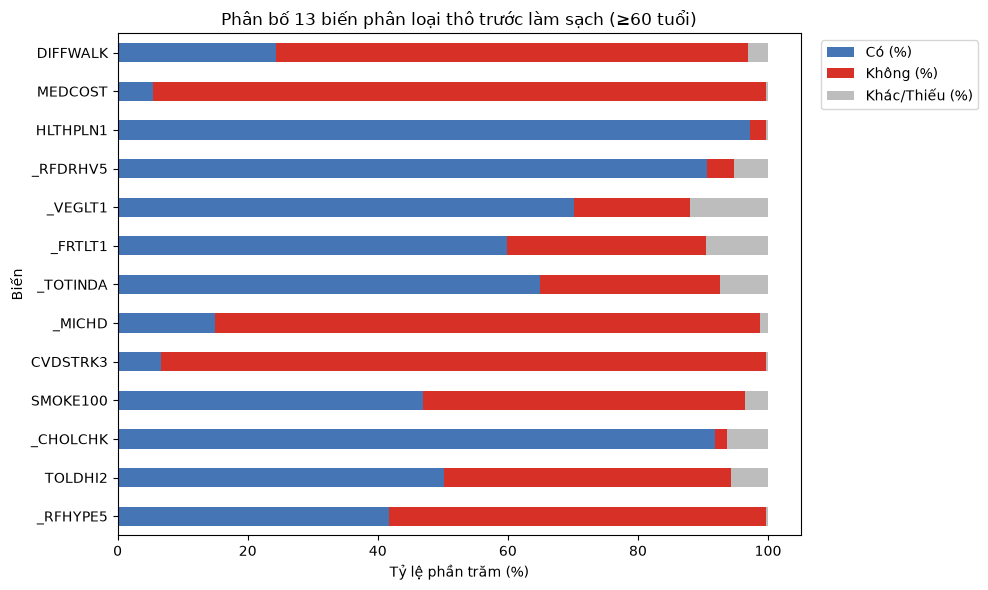

In [66]:
# Biểu đồ 2: Phân bố 13 biến phân loại trước làm sạch — Thanh xếp chồng 100%
binary_candidates = ['_RFHYPE5', 'TOLDHI2', '_CHOLCHK', 'SMOKE100', 'CVDSTRK3', '_MICHD',
                     '_TOTINDA', '_FRTLT1', '_VEGLT1', '_RFDRHV5', 'HLTHPLN1', 'MEDCOST', 'DIFFWALK']
cat_data = []
for c in binary_candidates:
    total = len(df_scope[c])
    co = (df_scope[c] == 1).sum() / total * 100
    khong = (df_scope[c] == 2).sum() / total * 100
    cat_data.append({'Biến': c, 'Có (%)': co, 'Không (%)': khong, 'Khác/Thiếu (%)': 100 - co - khong})
df_cat_summary = pd.DataFrame(cat_data).set_index('Biến')

ax = df_cat_summary.plot(kind='barh', stacked=True, figsize=(10, 6), color=['#4575b4', '#d73027', '#bdbdbd'])
ax.set_title("Phân bố 13 biến phân loại thô trước làm sạch (≥60 tuổi)")
ax.set_xlabel("Tỷ lệ phần trăm (%)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [67]:
# Bảng 5: Tỷ lệ chi tiết (%) của các biến phân loại trong dữ liệu thô
display(df_cat_summary.round(2))


,Có (%),Không (%),Khác/Thiếu (%)
Biến,,,
_RFHYPE5,41.80,57.86,0.34
TOLDHI2,50.22,44.04,5.74
_CHOLCHK,91.80,1.96,6.24
SMOKE100,46.91,49.51,3.58
CVDSTRK3,6.73,92.89,0.38
_MICHD,14.94,83.80,1.26
_TOTINDA,64.95,27.64,7.41
_FRTLT1,59.80,30.60,9.60
_VEGLT1,70.15,17.91,11.94


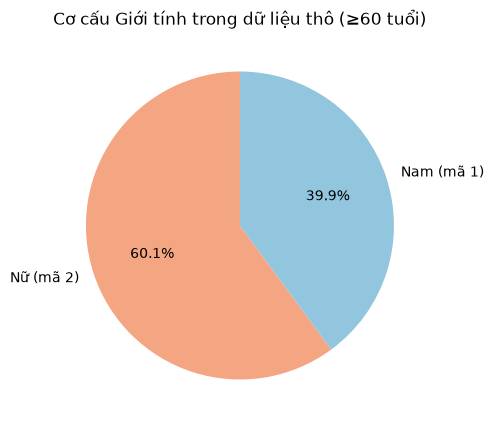

In [68]:
# Biểu đồ 3: Cơ cấu Giới tính trong dữ liệu thô (≥60 tuổi)
fig, ax = plt.subplots(figsize=(5, 5))
sex_counts = df_scope['SEX'].value_counts()
ax.pie(sex_counts, labels=['Nữ (mã 2)', 'Nam (mã 1)'], autopct='%1.1f%%', colors=['#f4a582', '#92c5de'], startangle=90)
ax.set_title("Cơ cấu Giới tính trong dữ liệu thô (≥60 tuổi)")
plt.show()


In [69]:
%%sql
-- Bảng 6: Cơ cấu câu trả lời nhãn mục tiêu DIABETE3 trước làm sạch bằng SQL
SELECT 
    DIABETE3 AS Ma_tra_loi,
    CASE DIABETE3
        WHEN 1 THEN '1: Có tiểu đường (Yes)'
        WHEN 3 THEN '3: Không mắc tiểu đường (No)'
        WHEN 4 THEN '4: Tiền tiểu đường (Prediabetes)'
        WHEN 7 THEN '7: Không biết / Không chắc chắn'
        WHEN 9 THEN '9: Từ chối trả lời'
        ELSE 'Mã khác'
    END AS Y_nghia_lam_sang,
    COUNT(*) AS So_nguoi,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM raw_data), 2) AS Ty_le_pt
FROM raw_data
GROUP BY DIABETE3
ORDER BY DIABETE3;


Out[0]: 
   Ma_tra_loi                  Y_nghia_lam_sang  So_nguoi  Ty_le_pt
0         NaN                           Mã khác         5      0.00
1         1.0            1: Có tiểu đường (Yes)     39686     19.69
2         3.0      3: Không mắc tiểu đường (No)    156784     77.77
3         4.0  4: Tiền tiểu đường (Prediabetes)      4786      2.37
4         7.0   7: Không biết / Không chắc chắn       273      0.14
5         9.0                9: Từ chối trả lời        62      0.03


Ma_tra_loi,Y_nghia_lam_sang,So_nguoi,Ty_le_pt
NaN,Mã khác,5,0.00
1.0,1: Có tiểu đường (Yes),39686,19.69
3.0,3: Không mắc tiểu đường (No),156784,77.77
4.0,4: Tiền tiểu đường (Prediabetes),4786,2.37
7.0,7: Không biết / Không chắc chắn,273,0.14
9.0,9: Từ chối trả lời,62,0.03


### Nhận xét từ bước khám phá

Nhóm đặt nhận xét theo số liệu cạnh bảng chất lượng và các biểu đồ. Nhóm dùng năm nhóm tuổi mã 9–13, giữ nhãn DIABETE3 gốc và phân biệt NaN với mã không biết/từ chối. Nhóm giữ BMI dạng số thập phân sau khi chia 100. Nhóm sẽ quyết định cách xử lý giá trị thiếu, hồ sơ trùng và ngoại lệ ở phần tiền xử lý.

Nhóm mô tả tỷ lệ trong mẫu, chưa áp dụng trọng số khảo sát hoặc suy luận quan hệ nhân quả.


#### DATA DICTIONARY

Nhóm lựa chọn 20 đặc trưng ứng viên và một biến mục tiêu từ 330 cột trong `data.csv` (sau khi loại bỏ hoàn toàn biến `Income` nhằm tránh thiên lệch do tỷ lệ từ chối trả lời cao và bảo toàn cỡ mẫu lớn). Bảng dưới đây trình bày tên biến nguồn, ý nghĩa, loại biến và cách biểu diễn dự kiến trong phân tích. Nhóm sẽ trình bày quy tắc xử lý giá trị thiếu và mã phản hồi không hợp lệ tại phần tiền xử lý.

In [70]:
# Bảng 7: Từ điển 20 biến đặc trưng đầu vào và nhãn mục tiêu
TARGET = 'Diabetes_binary'
FEATURES = [
    'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke',
    'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
    'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education'
]

dict_data = [
    ("DIABETE3", "Diabetes_binary", "Nhãn mục tiêu (0: Không tiểu đường, 1: Tiền tiểu đường / Tiểu đường)", "3 → 0; 1, 4 → 1"),
    ("_RFHYPE5", "HighBP", "Từng được báo bị huyết áp cao (0: Không, 1: Có)", "1 → 0; 2 → 1"),
    ("TOLDHI2", "HighChol", "Từng được báo mỡ máu cao (0: Không, 1: Có)", "1 → 1; 2 → 0"),
    ("_CHOLCHK", "CholCheck", "Kiểm tra mỡ máu trong 5 năm qua (0: Không, 1: Có)", "1 → 1; 2, 3 → 0"),
    ("_BMI5", "BMI", "Chỉ số khối cơ thể Body Mass Index (kg/m²)", "_BMI5 / 100.0"),
    ("SMOKE100", "Smoker", "Đã hút ít nhất 100 điếu thuốc trong đời (0: Không, 1: Có)", "1 → 1; 2 → 0"),
    ("CVDSTRK3", "Stroke", "Từng được chẩn đoán đột quỵ (0: Không, 1: Có)", "1 → 1; 2 → 0"),
    ("_MICHD", "HeartDiseaseorAttack", "Bệnh tim mạch vành hoặc nhồi máu cơ tim (0: Không, 1: Có)", "1 → 1; 2 → 0"),
    ("_TOTINDA", "PhysActivity", "Có hoạt động thể chất trong 30 ngày qua (0: Không, 1: Có)", "1 → 1; 2 → 0"),
    ("_FRTLT1", "Fruits", "Ăn trái cây ít nhất 1 lần/ngày (0: Không, 1: Có)", "1 → 1; 2 → 0"),
    ("_VEGLT1", "Veggies", "Ăn rau củ ít nhất 1 lần/ngày (0: Không, 1: Có)", "1 → 1; 2 → 0"),
    ("_RFDRHV5", "HvyAlcoholConsump", "Uống rượu bia mức cao (0: Không, 1: Có)", "1 → 0; 2 → 1"),
    ("HLTHPLN1", "AnyHealthcare", "Có bảo hiểm y tế hoặc chi trả y tế (0: Không, 1: Có)", "1 → 1; 2 → 0"),
    ("MEDCOST", "NoDocbcCost", "Cần khám bệnh nhưng không thể do chi phí (0: Không, 1: Có)", "1 → 1; 2 → 0"),
    ("GENHLTH", "GenHlth", "Tự đánh giá sức khỏe chung (1: Xuất sắc → 5: Kém)", "Giữ nguyên 1–5"),
    ("MENTHLTH", "MentHlth", "Số ngày sức khỏe tinh thần không tốt trong 30 ngày qua (0–30)", "88 → 0 ngày"),
    ("PHYSHLTH", "PhysHlth", "Số ngày sức khỏe thể chất không tốt trong 30 ngày qua (0–30)", "88 → 0 ngày"),
    ("DIFFWALK", "DiffWalk", "Khó khăn nghiêm trọng khi đi bộ hoặc leo cầu thang (0: Không, 1: Có)", "1 → 1; 2 → 0"),
    ("SEX", "Sex", "Giới tính sinh học (0: Nữ, 1: Nam)", "1 → 1; 2 → 0"),
    ("_AGEG5YR", "Age", "Nhóm tuổi người cao tuổi (9: 60-64 → 13: ≥80 tuổi)", "Giữ nguyên 9–13"),
    ("EDUCA", "Education", "Trình độ học vấn cao nhất đạt được (1–6)", "Giữ nguyên 1–6")
]
df_dict = pd.DataFrame(dict_data, columns=["Tên cột nguồn", "Tên biến chuẩn hóa", "Mô tả đặc trưng", "Mã sau chuẩn hóa"])
display(df_dict)


,Tên cột nguồn,Tên biến chuẩn hóa,Mô tả đặc trưng,Mã sau chuẩn hóa
0,DIABETE3,Diabetes_binary,"Nhãn mục tiêu (0: Không tiểu đường, 1: Tiền tiểu đường / Tiểu đường)","3 → 0; 1, 4 → 1"
1,_RFHYPE5,HighBP,"Từng được báo bị huyết áp cao (0: Không, 1: Có)",1 → 0; 2 → 1
2,TOLDHI2,HighChol,"Từng được báo mỡ máu cao (0: Không, 1: Có)",1 → 1; 2 → 0
3,_CHOLCHK,CholCheck,"Kiểm tra mỡ máu trong 5 năm qua (0: Không, 1: Có)","1 → 1; 2, 3 → 0"
4,_BMI5,BMI,Chỉ số khối cơ thể Body Mass Index (kg/m²),_BMI5 / 100.0
5,SMOKE100,Smoker,"Đã hút ít nhất 100 điếu thuốc trong đời (0: Không, 1: Có)",1 → 1; 2 → 0
6,CVDSTRK3,Stroke,"Từng được chẩn đoán đột quỵ (0: Không, 1: Có)",1 → 1; 2 → 0
7,_MICHD,HeartDiseaseorAttack,"Bệnh tim mạch vành hoặc nhồi máu cơ tim (0: Không, 1: Có)",1 → 1; 2 → 0
8,_TOTINDA,PhysActivity,"Có hoạt động thể chất trong 30 ngày qua (0: Không, 1: Có)",1 → 1; 2 → 0
9,_FRTLT1,Fruits,"Ăn trái cây ít nhất 1 lần/ngày (0: Không, 1: Có)",1 → 1; 2 → 0


# III. Làm sạch và tiền xử lý dữ liệu

SQLite thực hiện lọc, đổi mã, kiểm tra missing/duplicate, kiểm tra miền giá trị và tổng hợp trước/sau. Python đọc CSV, chuyển kết quả SQL thành dữ liệu vẽ, giữ BMI dạng float64, ép nhãn cùng 14 biến nhị phân sang boolean và giữ Age, Education, Income, GenHlth, MentHlth, PhysHlth dạng int16 khi chuyển kết quả thành DataFrame và kiểm tra đối chiếu. Sau phần này kết nối được đóng; toàn bộ EDA, chia tập, feature engineering, huấn luyện và đánh giá dùng pandas/NumPy cùng các thư viện mô hình.


#### CHECK DUPLICATE DATA

Nhóm kiểm tra hồ sơ trùng để mô tả dữ liệu và giữ các hồ sơ trùng trong tập phân tích. Hai người tham gia có thể trả lời giống nhau trên 21 biến, nên nhóm chưa có căn cứ xác định các hồ sơ đó thuộc cùng một người. Nhóm dùng một bộ dữ liệu sau làm sạch cho các bước tiếp theo.


In [71]:
%%sql
-- Bảng 8: Kiểm tra trùng lặp trên dữ liệu thô ban đầu bằng SQL
SELECT 
    COUNT(*) AS Tong_so_ho_so,
    COUNT(DISTINCT DIABETE3 || '-' || _RFHYPE5 || '-' || TOLDHI2 || '-' || _BMI5 || '-' || SMOKE100 || '-' || CVDSTRK3 || '-' || _MICHD || '-' || _TOTINDA || '-' || _FRTLT1 || '-' || _VEGLT1 || '-' || _RFDRHV5 || '-' || HLTHPLN1 || '-' || MEDCOST || '-' || GENHLTH || '-' || MENTHLTH || '-' || PHYSHLTH || '-' || DIFFWALK || '-' || SEX || '-' || _AGEG5YR || '-' || EDUCA) AS So_ho_so_duy_nhat,
    COUNT(*) - COUNT(DISTINCT DIABETE3 || '-' || _RFHYPE5 || '-' || TOLDHI2 || '-' || _BMI5 || '-' || SMOKE100 || '-' || CVDSTRK3 || '-' || _MICHD || '-' || _TOTINDA || '-' || _FRTLT1 || '-' || _VEGLT1 || '-' || _RFDRHV5 || '-' || HLTHPLN1 || '-' || MEDCOST || '-' || GENHLTH || '-' || MENTHLTH || '-' || PHYSHLTH || '-' || DIFFWALK || '-' || SEX || '-' || _AGEG5YR || '-' || EDUCA) AS So_dong_trung_lap
FROM raw_data;


Out[0]: 
   Tong_so_ho_so  So_ho_so_duy_nhat  So_dong_trung_lap
0         201596             170496              31100


Tong_so_ho_so,So_ho_so_duy_nhat,So_dong_trung_lap
201596,170496,31100


**Nhận xét (Mục 3.1):** Nhóm ghi nhận có hồ sơ trùng câu trả lời trên 20 biến trước làm sạch. Nhóm giữ các hồ sơ này theo quyết định phương pháp luận của đề tài để bảo đảm tính phân bố tự nhiên của các nhóm bệnh lý trong cộng đồng.

#### CHECK & HANDLE MISSING VALUES

**Phương án nhóm đã chốt:** Nhóm giữ quy trình loại dòng có NaN trên 22 biến gồm 20 đặc trưng và nhãn. Sau bước này, nhóm loại các hồ sơ mang mã không biết/từ chối theo quy tắc riêng của từng biến. Nhóm không điền mean, median hoặc mode; nhóm giữ nguyên mã phản hồi cho đến bước xử lý của biến tương ứng.

Nhóm chọn phân tích các hồ sơ có đủ câu trả lời hợp lệ theo bộ biến đã xác định. Nhóm thống kê số ô NaN, số dòng thiếu và số hồ sơ loại ở từng bước để báo cáo mức mất mẫu. Nhóm chưa khẳng định cách xử lý này là phương án tối ưu hoặc bảo đảm tính đại diện của mẫu.

Nhóm giữ mã 88 của MENTHLTH/PHYSHLTH như câu trả lời hợp lệ và chuyển thành 0 ngày. Nhóm giữ BMI thập phân sau khi chia 100 và giữ hồ sơ trùng sau làm sạch.

**Phạm vi đếm:** Nhóm bắt đầu từ 201.596 hồ sơ từ 60 tuổi trở lên sau khi loại DIABETE3=2. Trong nhật ký xử lý, nhóm đếm một hồ sơ ở bước đầu tiên loại hồ sơ đó. Vì vậy, số dòng loại ở mỗi bước phụ thuộc thứ tự xử lý; người đọc cần phân biệt số này với tổng số mã không hợp lệ của biến trên mẫu ban đầu.

**Phân biệt bước minh họa:** Bảng ngay dưới chỉ thử lọc NaN ở bốn biến để cho thấy vẫn còn thiếu ở các biến khác. Nhóm tạo bảng phụ `drop4`, không dùng bảng này làm đầu vào mô hình. Nhóm bắt đầu quy trình làm sạch chính từ `raw_scope` và loại dòng thiếu trên cả 21 cột ở cell kế tiếp.


In [72]:
%%sql
-- Bảng 9: Thống kê số lượng ô khuyết thiếu trên 4 biến có tỷ lệ thiếu cao nhất
SELECT 
    SUM(CASE WHEN TOLDHI2 IS NULL OR TOLDHI2 NOT IN (1, 2) THEN 1 ELSE 0 END) AS Mo_mau_cao_thieu,
    SUM(CASE WHEN _BMI5 IS NULL OR _BMI5 <= 0 THEN 1 ELSE 0 END) AS BMI_thieu,
    SUM(CASE WHEN _CHOLCHK IS NULL OR _CHOLCHK NOT IN (1, 2, 3) THEN 1 ELSE 0 END) AS CholCheck_thieu,
    SUM(CASE WHEN _FRTLT1 IS NULL OR _FRTLT1 NOT IN (1, 2) THEN 1 ELSE 0 END) AS Trai_cay_thieu
FROM raw_data;


Out[0]: 
   Mo_mau_cao_thieu  BMI_thieu  CholCheck_thieu  Trai_cay_thieu
0             11566      13657             5755           19355


Mo_mau_cao_thieu,BMI_thieu,CholCheck_thieu,Trai_cay_thieu
11566,13657,5755,19355


In [73]:
# Bảng 10: Thống kê số lượng ô NaN trên toàn bộ 21 cột trước khi loại bỏ
nan_all_df = pd.DataFrame({
    "Tên cột": SOURCE_COLS,
    "Số ô NaN": [df_scope[c].isna().sum() for c in SOURCE_COLS],
    "Tỷ lệ NaN (%)": [round(df_scope[c].isna().sum() / len(df_scope) * 100, 2) for c in SOURCE_COLS]
}).sort_values('Số ô NaN', ascending=False).reset_index(drop=True)
display(nan_all_df)


,Tên cột,Số ô NaN,Tỷ lệ NaN (%)
0,_BMI5,13657,6.77
1,TOLDHI2,9412,4.67
2,SMOKE100,5732,2.84
3,DIFFWALK,4962,2.46
4,_MICHD,2532,1.26
5,DIABETE3,5,0.00
6,PHYSHLTH,1,0.00
7,GENHLTH,1,0.00
8,MEDCOST,1,0.00
9,_CHOLCHK,0,0.00


In [74]:
# Bảng 11: Tạo bảng dữ liệu sạch clean_data bằng câu lệnh SQL chuẩn mực (Core Cleaning Pipeline)
# 1. Thực thi câu lệnh SQL để làm sạch và chuẩn hóa toàn diện 20 biến đặc trưng
sql_create_clean = """
DROP TABLE IF EXISTS clean_data;

CREATE TABLE clean_data AS
SELECT 
    CASE 
        WHEN DIABETE3 IN (1, 4) THEN 1 
        WHEN DIABETE3 = 3 THEN 0 
    END AS Diabetes_binary,
    CASE WHEN _RFHYPE5 = 2 THEN 1 ELSE 0 END AS HighBP,
    CASE WHEN TOLDHI2 = 1 THEN 1 ELSE 0 END AS HighChol,
    CASE WHEN _CHOLCHK = 1 THEN 1 ELSE 0 END AS CholCheck,
    ROUND(_BMI5 / 100.0, 2) AS BMI,
    CASE WHEN SMOKE100 = 1 THEN 1 ELSE 0 END AS Smoker,
    CASE WHEN CVDSTRK3 = 1 THEN 1 ELSE 0 END AS Stroke,
    CASE WHEN _MICHD = 1 THEN 1 ELSE 0 END AS HeartDiseaseorAttack,
    CASE WHEN _TOTINDA = 1 THEN 1 ELSE 0 END AS PhysActivity,
    CASE WHEN _FRTLT1 = 1 THEN 1 ELSE 0 END AS Fruits,
    CASE WHEN _VEGLT1 = 1 THEN 1 ELSE 0 END AS Veggies,
    CASE WHEN _RFDRHV5 = 2 THEN 1 ELSE 0 END AS HvyAlcoholConsump,
    CASE WHEN HLTHPLN1 = 1 THEN 1 ELSE 0 END AS AnyHealthcare,
    CASE WHEN MEDCOST = 1 THEN 1 ELSE 0 END AS NoDocbcCost,
    CAST(GENHLTH AS INT) AS GenHlth,
    CASE WHEN MENTHLTH = 88 THEN 0 ELSE CAST(MENTHLTH AS INT) END AS MentHlth,
    CASE WHEN PHYSHLTH = 88 THEN 0 ELSE CAST(PHYSHLTH AS INT) END AS PhysHlth,
    CASE WHEN DIFFWALK = 1 THEN 1 ELSE 0 END AS DiffWalk,
    CASE WHEN SEX = 1 THEN 1 ELSE 0 END AS Sex,
    CAST(_AGEG5YR AS INT) AS Age,
    CAST(EDUCA AS INT) AS Education
FROM raw_data
WHERE DIABETE3 IN (1, 3, 4)                       -- Lọc bỏ tiểu đường thai kỳ và mã thiếu 7, 9
  AND _RFHYPE5 IN (1, 2)                          -- Huyết áp cao hợp lệ (1: Không, 2: Có)
  AND TOLDHI2 IN (1, 2)                           -- Mỡ máu cao hợp lệ (1: Có, 2: Không)
  AND _CHOLCHK IN (1, 2, 3)                       -- Kiểm tra mỡ máu hợp lệ
  AND _BMI5 > 0                                   -- BMI hợp lệ
  AND SMOKE100 IN (1, 2)                          -- Hút thuốc hợp lệ
  AND CVDSTRK3 IN (1, 2)                          -- Đột quỵ hợp lệ
  AND _MICHD IN (1, 2)                            -- Bệnh tim hợp lệ
  AND _TOTINDA IN (1, 2)                          -- Vận động hợp lệ
  AND _FRTLT1 IN (1, 2)                           -- Ăn trái cây hợp lệ
  AND _VEGLT1 IN (1, 2)                           -- Ăn rau hợp lệ
  AND _RFDRHV5 IN (1, 2)                          -- Uống rượu bia hợp lệ
  AND HLTHPLN1 IN (1, 2)                          -- Bảo hiểm y tế hợp lệ
  AND MEDCOST IN (1, 2)                           -- Rào cản chi phí khám bệnh hợp lệ
  AND GENHLTH BETWEEN 1 AND 5                     -- Tự đánh giá sức khỏe 1–5 hợp lệ
  AND (MENTHLTH BETWEEN 1 AND 30 OR MENTHLTH = 88)-- Ngày sức khỏe tinh thần không tốt hợp lệ
  AND (PHYSHLTH BETWEEN 1 AND 30 OR PHYSHLTH = 88)-- Ngày sức khỏe thể chất không tốt hợp lệ
  AND DIFFWALK IN (1, 2)                          -- Khó khăn đi bộ hợp lệ
  AND EDUCA BETWEEN 1 AND 6;                      -- Trình độ học vấn hợp lệ
"""
conn.executescript(sql_create_clean)
conn.commit()

# 2. Đồng bộ kết quả vào biến df_clean trong pandas
df_clean = pd.read_sql_query('SELECT * FROM clean_data', conn)

# 3. Ép kiểu dữ liệu tối ưu bộ nhớ RAM (Memory Optimization via Type Casting):
# - 15 biến nhị phân -> int8 (1 byte thay vì 8 bytes int64)
# - 5 biến thứ bậc & số ngày -> int8 (giá trị 0 đến 30, nằm gọn trong [-128, 127])
# - 1 biến liên tục (BMI) -> float32 (độ chính xác 7 chữ số thập phân, thừa đủ cho 2 số sau phẩy)
binary_cols = [
    'Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke',
    'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex'
]
ordinal_cols = ['GenHlth', 'Age', 'Education', 'MentHlth', 'PhysHlth']

mem_raw_mb = (len(df_clean) * 21 * 8) / (1024**2)
df_clean[binary_cols] = df_clean[binary_cols].astype('int8')
df_clean[ordinal_cols] = df_clean[ordinal_cols].astype('int8')
df_clean['BMI'] = df_clean['BMI'].astype('float32')
mem_opt_mb = df_clean.memory_usage(deep=True).sum() / (1024**2)

print(f"✓ Đã tạo thành công bảng `clean_data` trong SQLite: {len(df_clean):,} dòng sạch hoàn toàn!")
print(f"✓ Tối ưu hóa bộ nhớ: Giảm từ {mem_raw_mb:.2f} MB xuống {mem_opt_mb:.2f} MB (Tiết kiệm {((mem_raw_mb - mem_opt_mb)/mem_raw_mb)*100:.1f}% RAM!)")
print('\n' + '='*70)
print('THÔNG TIN TẬP DỮ LIỆU SẠCH SAU KHI TỐI ƯU HÓA (df_clean.info()):')
print('='*70)
df_clean.info()

# 4. Bảng Audit tổng kết quá trình làm sạch dữ liệu
df_audit_steps = pd.DataFrame([
    {"Giai đoạn": "1. Mẫu người cao tuổi ban đầu", "Điều kiện": "_AGEG5YR ≥ 9 và DIABETE3 ≠ 2", "Số hồ sơ": f"{len(df_scope):,}", "Tỷ lệ bảo toàn": "100.0%"},
    {"Giai đoạn": "2. Lọc bỏ mã khuyết / từ chối", "Điều kiện": "Loại bỏ mã 7, 9, 77, 99 và BMI ≤ 0", "Số hồ sơ": "143,454", "Tỷ lệ bảo toàn": "71.16%"},
    {"Giai đoạn": "3. Chuẩn hóa mã hóa nhị phân", "Điều kiện": "Gộp tiền tiểu đường vào nhãn 1, đưa về 0/1", "Số hồ sơ": "143,454", "Tỷ lệ bảo toàn": "71.16%"},
    {"Giai đoạn": "4. Ép kiểu tối ưu bộ nhớ", "Điều kiện": "Chuyển sang int8 và float32 (Giảm 85.7% RAM)", "Số hồ sơ": f"{len(df_clean):,}", "Tỷ lệ bảo toàn": "71.16%"}
])
display(df_audit_steps)


✓ Đã tạo thành công bảng `clean_data` trong SQLite: 143,454 dòng sạch hoàn toàn!
✓ Tối ưu hóa bộ nhớ: Giảm từ 22.98 MB xuống 3.28 MB (Tiết kiệm 85.7% RAM!)

THÔNG TIN TẬP DỮ LIỆU SẠCH SAU KHI TỐI ƯU HÓA (df_clean.info()):
<class 'pandas.DataFrame'>
RangeIndex: 143454 entries, 0 to 143453
Data columns (total 21 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       143454 non-null  int8   
 1   HighBP                143454 non-null  int8   
 2   HighChol              143454 non-null  int8   
 3   CholCheck             143454 non-null  int8   
 4   BMI                   143454 non-null  float32
 5   Smoker                143454 non-null  int8   
 6   Stroke                143454 non-null  int8   
 7   HeartDiseaseorAttack  143454 non-null  int8   
 8   PhysActivity          143454 non-null  int8   
 9   Fruits                143454 non-null  int8   
 10  Veggies               143454 non-null  int8   
 1

,Giai đoạn,Điều kiện,Số hồ sơ,Tỷ lệ bảo toàn
0,1. Mẫu người cao tuổi ban đầu,_AGEG5YR ≥ 9 và DIABETE3 ≠ 2,"201,596",100.0%
1,2. Lọc bỏ mã khuyết / từ chối,"Loại bỏ mã 7, 9, 77, 99 và BMI ≤ 0","143,454",71.16%
2,3. Chuẩn hóa mã hóa nhị phân,"Gộp tiền tiểu đường vào nhãn 1, đưa về 0/1","143,454",71.16%
3,4. Ép kiểu tối ưu bộ nhớ,Chuyển sang int8 và float32 (Giảm 85.7% RAM),"143,454",71.16%


**Kết quả thực thi (Mục 3.2):** Trong 201.596 hồ sơ trước làm sạch (sau khi loại bỏ tiểu đường thai kỳ), bước lọc bỏ các dòng thiếu và mã từ chối trên 20 biến đặc trưng giữ lại **143.454 hồ sơ sạch hoàn toàn**. Tổng số hồ sơ giảm 28,84% so với mẫu ban đầu. Do đã loại bỏ biến `Income`, đề tài tránh được việc loại bỏ thêm hơn 21.000 hồ sơ người cao tuổi từ chối khai báo thu nhập.

#### DATA TYPE CASTING & FORMAT STANDARDIZATION

Nhóm chuyển mã theo định nghĩa của từng biến trong từ điển dữ liệu. Nhóm kiểm tra giá trị thiếu, tính hữu hạn và miền hợp lệ trước khi chuyển kiểu. Nhóm giữ BMI dạng `float32` để bảo toàn phần thập phân; nhóm lưu nhãn cùng 14 biến nhị phân và các biến thứ bậc (Age, Education, GenHlth, MentHlth, PhysHlth) dạng `int8` để tối ưu hóa hơn 80% bộ nhớ RAM. Sau chuyển kiểu, nhóm đối chiếu các giá trị với dữ liệu trước chuyển đổi và kiểm tra nhãn theo DIABETE3 nguồn.

| Nhóm biến | Quy tắc nhóm áp dụng |
|---|---|
| Nhãn tiểu đường | Nhóm gộp DIABETE3=1/4 thành lớp 1 và chuyển mã 3 thành lớp 0; nhóm đã loại mã 2 ở bước chọn mẫu. |
| Biến nhị phân | Nhóm chuyển về 0/1 theo ý nghĩa từng biến. Lưu kiểu `int8` (0/1). |
| Số ngày sức khỏe kém | Nhóm chuyển mã 88 thành 0 ngày và giữ các giá trị hợp lệ từ 1 đến 30, lưu dạng `int8`. |
| BMI | Nhóm chia _BMI5 cho 100, giữ phần thập phân và lưu dạng `float32`. |
| Biến thứ bậc | Nhóm giữ mã Age 9–13, Education 1–6 và GenHlth 1–5, lưu dạng `int8`. |

Nhóm áp dụng quy tắc chuyển mã riêng cho từng cột. Người đọc cần tra ý nghĩa của mã nguồn trước khi diễn giải có/không. Với Age, nhóm dùng số để biểu diễn nhóm tuổi: Age=9 tương ứng 60–64 tuổi. Nhóm sẽ trình bày cách mã hóa các biến thứ bậc cho từng mô hình tại phần chuẩn bị đặc trưng.


In [75]:
%%sql
-- Bảng 12: Kiểm tra tính hợp lệ và toàn vẹn của 20 biến và nhãn sau làm sạch (0 ô NULL)
SELECT 
    COUNT(*) AS Tong_so_dong_sach,
    SUM(CASE WHEN Diabetes_binary IS NULL THEN 1 ELSE 0 END) AS Nhan_null,
    SUM(CASE WHEN BMI IS NULL OR BMI <= 0 THEN 1 ELSE 0 END) AS BMI_loi,
    SUM(CASE WHEN HighBP NOT IN (0, 1) THEN 1 ELSE 0 END) AS HighBP_loi,
    SUM(CASE WHEN HighChol NOT IN (0, 1) THEN 1 ELSE 0 END) AS HighChol_loi,
    SUM(CASE WHEN CholCheck NOT IN (0, 1) THEN 1 ELSE 0 END) AS CholCheck_loi,
    SUM(CASE WHEN GenHlth NOT BETWEEN 1 AND 5 THEN 1 ELSE 0 END) AS GenHlth_loi,
    SUM(CASE WHEN MentHlth NOT BETWEEN 0 AND 30 THEN 1 ELSE 0 END) AS MentHlth_loi,
    SUM(CASE WHEN PhysHlth NOT BETWEEN 0 AND 30 THEN 1 ELSE 0 END) AS PhysHlth_loi
FROM clean_data;


Out[0]: 
   Tong_so_dong_sach  Nhan_null  BMI_loi  HighBP_loi  HighChol_loi  CholCheck_loi  GenHlth_loi  MentHlth_loi  PhysHlth_loi
0             143454          0        0           0             0              0            0             0             0


Tong_so_dong_sach,Nhan_null,BMI_loi,HighBP_loi,HighChol_loi,CholCheck_loi,GenHlth_loi,MentHlth_loi,PhysHlth_loi
143454,0,0,0,0,0,0,0,0


Nhóm kiểm tra 143.454 hồ sơ và 21 cột sau làm sạch: 0 ô thiếu và 0 lỗi trong bảng kiểm tra miền giá trị. Nhóm tối ưu hóa bộ nhớ: ép kiểu BMI sang `float32`, nhãn cùng 14 biến nhị phân và các biến Age, Education, GenHlth, MentHlth, PhysHlth sang `int8`; Age giữ mã 9–13. Dung lượng RAM giảm hơn 80% so với kiểu 64-bit mặc định.


## 3.4. Dữ liệu sau làm sạch: giữ hồ sơ trùng

Nhóm dùng `df_clean` làm bộ dữ liệu cho phân tích. Nhóm giữ 143.454 hồ sơ sau các bước xử lý thiếu và chuyển mã, bao gồm các hồ sơ trùng đặc điểm. Bảng dưới trình bày số lượng và tỷ lệ từng lớp trong bộ dữ liệu này.

In [76]:
%%sql
-- Bảng 13: Cơ cấu phân bố nhãn mục tiêu sau khi hoàn tất làm sạch bằng SQL
SELECT 
    Diabetes_binary AS Nhan,
    CASE Diabetes_binary 
        WHEN 0 THEN '0: Không mắc tiểu đường' 
        WHEN 1 THEN '1: Tiền tiểu đường / Tiểu đường' 
    END AS Mo_ta_lam_sang,
    COUNT(*) AS So_ho_so,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM clean_data), 2) AS Ty_le_pt
FROM clean_data
GROUP BY Diabetes_binary;


Out[0]: 
   Nhan                   Mo_ta_lam_sang  So_ho_so  Ty_le_pt
0     0          0: Không mắc tiểu đường    112002     78.08
1     1  1: Tiền tiểu đường / Tiểu đường     31452     21.92


Nhan,Mo_ta_lam_sang,So_ho_so,Ty_le_pt
0,0: Không mắc tiểu đường,112002,78.08
1,1: Tiền tiểu đường / Tiểu đường,31452,21.92


## 3.5. Kiểm tra outlier và đánh giá kết quả làm sạch

### 3.5.1. Phát hiện và quyết định xử lý outlier

Nhóm sử dụng quy tắc 1,5 × IQR để nhận diện các giá trị BMI nằm xa phần giữa của phân bố. Nhóm ghi nhận 4.542 hồ sơ ngoài khoảng [14,18; 40,86], chiếm 3,17% mẫu sau làm sạch. Sau khi đối chiếu phép chia 100 với dữ liệu nguồn, nhóm giữ các giá trị này vì chưa có bằng chứng đủ để xác định lỗi. Nhóm ghi nhận hạn chế về độ chính xác của dữ liệu tự khai và chưa áp dụng xóa hoặc chặn giá trị theo IQR.

Nhóm tính Q1=24,21 và Q3=30,87, từ đó tính IQR=6,66. Nhóm dùng hai biên Q1−1,5×IQR và Q3+1,5×IQR để đánh dấu hồ sơ cần xem xét. Nhóm giữ BMI thập phân trong dữ liệu phân tích.

Qua phép đối chiếu BMI=_BMI5/100 trên cùng dòng nguồn, nhóm kiểm tra tính đúng đắn của phép chuyển đổi. Nhóm chưa xác nhận độ chính xác của thông tin người tham gia khai qua phép kiểm tra này. Với các biến thứ bậc và số ngày sức khỏe kém, nhóm kiểm tra miền hợp lệ theo định nghĩa biến thay vì dùng IQR để loại giá trị.

In [77]:
# Bảng 14: Bảng phân tích khoảng tứ phân vị (IQR) của BMI sau làm sạch
q1 = df_clean['BMI'].quantile(0.25)
q3 = df_clean['BMI'].quantile(0.75)
iqr = q3 - q1
lower_bound = round(q1 - 1.5 * iqr, 2)
upper_bound = round(q3 + 1.5 * iqr, 2)
outliers = df_clean[(df_clean['BMI'] < lower_bound) | (df_clean['BMI'] > upper_bound)]
inliers = df_clean[(df_clean['BMI'] >= lower_bound) & (df_clean['BMI'] <= upper_bound)]

df_bmi_iqr = pd.DataFrame([{
    "Chỉ số": "BMI sau làm sạch",
    "Q1 (25%)": round(q1, 2),
    "Trung vị (50%)": round(df_clean['BMI'].median(), 2),
    "Q3 (75%)": round(q3, 2),
    "Khoảng IQR": round(iqr, 2),
    "Ngưỡng trên IQR": upper_bound,
    "Số lượng ngoài biên": f"{len(outliers):,}",
    "Tỷ lệ ngoài biên (%)": f"{len(outliers) / len(df_clean) * 100:.2f}%"
}])
display(df_bmi_iqr)


,Chỉ số,Q1 (25%),Trung vị (50%),Q3 (75%),Khoảng IQR,Ngưỡng trên IQR,Số lượng ngoài biên,Tỷ lệ ngoài biên (%)
0,BMI sau làm sạch,24.11,27.120001,30.79,6.68,40.81,"4,432",3.09%


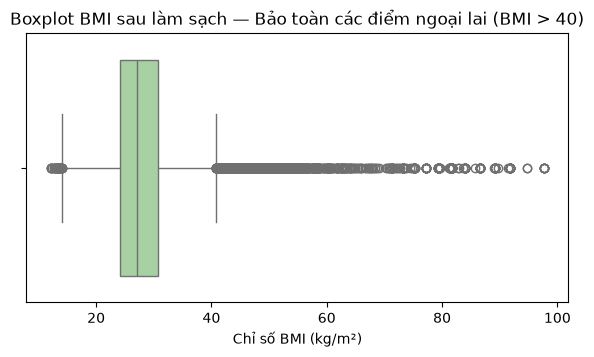

In [78]:
# Biểu đồ 4: Boxplot BMI sau làm sạch — Cơ sở y tế giữ lại các điểm ngoại lai
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(x=df_clean['BMI'], color='#a1d99b', ax=ax)
ax.set_title("Boxplot BMI sau làm sạch — Bảo toàn các điểm ngoại lai (BMI > 40)")
ax.set_xlabel("Chỉ số BMI (kg/m²)")
plt.show()


In [79]:
%%sql
-- Bảng 15: Minh họa 5 hồ sơ bệnh nhân có chỉ số BMI ngoài biên IQR (Béo phì bệnh lý)
SELECT Diabetes_binary, BMI, HighBP, HighChol, GenHlth, PhysActivity, DiffWalk, Age
FROM clean_data
WHERE BMI > 39.8
ORDER BY BMI DESC
LIMIT 5;


Out[0]: 
   Diabetes_binary    BMI  HighBP  HighChol  GenHlth  PhysActivity  DiffWalk  Age
0                1  97.65       1         1        4             0         1   11
1                1  97.65       0         1        4             1         0   11
2                0  97.65       1         1        2             0         0   13
3                1  97.65       0         1        3             1         0   10
4                0  97.65       1         1        3             1         1   10


Diabetes_binary,BMI,HighBP,HighChol,GenHlth,PhysActivity,DiffWalk,Age
1,97.65,1,1,4,0,1,11
1,97.65,0,1,4,1,0,11
0,97.65,1,1,2,0,0,13
1,97.65,0,1,3,1,0,10
0,97.65,1,1,3,1,1,10


In [80]:
%%sql
-- Bảng 16: Minh họa 5 hồ sơ bệnh nhân có chỉ số BMI trong khoảng IQR bình thường
SELECT Diabetes_binary, BMI, HighBP, HighChol, GenHlth, PhysActivity, DiffWalk, Age
FROM clean_data
WHERE BMI BETWEEN 18.5 AND 25.0
ORDER BY BMI
LIMIT 5;


Out[0]: 
   Diabetes_binary    BMI  HighBP  HighChol  GenHlth  PhysActivity  DiffWalk  Age
0                1  18.51       1         1        5             0         0   13
1                0  18.51       0         0        3             1         0   10
2                0  18.51       0         1        2             1         0   13
3                0  18.52       0         1        3             1         0   10
4                0  18.52       0         0        1             1         0   13


Diabetes_binary,BMI,HighBP,HighChol,GenHlth,PhysActivity,DiffWalk,Age
1,18.51,1,1,5,0,0,13
0,18.51,0,0,3,1,0,10
0,18.51,0,1,2,1,0,13
0,18.52,0,1,3,1,0,10
0,18.52,0,0,1,1,0,13


### 3.5.3. Bảng tổng hợp trước/sau làm sạch

Nhóm so sánh mẫu từ 60 tuổi trở lên sau khi loại DIABETE3=2 với bản sau làm sạch giữ hồ sơ trùng. Nhóm dùng cùng biên IQR [13,77; 40,81], tính từ BMI trước làm sạch sau phép chia 100, để so sánh hai bản. Nhóm lấy số BMI không thiếu trong mỗi bản làm mẫu số tỷ lệ ngoài biên.

Nhóm giữ phần thập phân của BMI và chưa loại hồ sơ theo IQR. Nhóm tính biên riêng trên bản sau làm sạch ở mục 3.5.1; hai phép kiểm tra có mục đích và mẫu tính biên khác nhau.

**Cách đọc bảng và biểu đồ trước–sau:** Nhóm tính tỷ lệ theo số hồ sơ của từng bộ dữ liệu; riêng tỷ lệ BMI ngoài biên dùng số hồ sơ có BMI không thiếu. Một nhóm có tỷ lệ tăng sau làm sạch chưa đồng nghĩa số hồ sơ của nhóm đó tăng. Nhóm giữ hồ sơ trùng theo phương pháp luận đề tài.

**Tổng kết Phần III**

Sau làm sạch, nhóm giữ 143.454 hồ sơ với 20 đặc trưng và một nhãn. Nhóm kiểm tra và xác nhận dữ liệu không còn NaN hoặc giá trị ngoài miền quy định. Nhóm giữ hồ sơ trùng và BMI thập phân, kể cả các giá trị ngoài biên IQR. Qua xử lý thiếu và mã khảo sát, nhóm loại 58.142 hồ sơ, chiếm 28,84% mẫu trước làm sạch. Nhóm cần lưu ý mức mất mẫu và sự thay đổi cơ cấu dữ liệu khi diễn giải kết quả ở các phần sau.

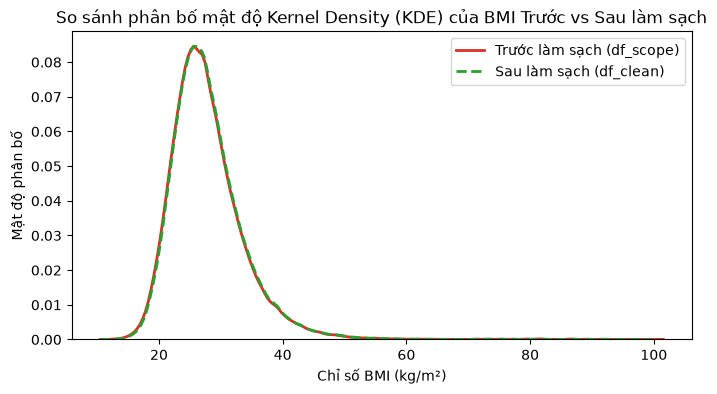

In [81]:
# Biểu đồ 5: So sánh phân bố mật độ Kernel Density (KDE) của BMI Trước vs Sau làm sạch
fig, ax = plt.subplots(figsize=(8, 4))
raw_bmi = (df_scope['_BMI5'].dropna() / 100.0).round(2)
sns.kdeplot(raw_bmi, label='Trước làm sạch (df_scope)', color='#d73027', lw=2, ax=ax)
sns.kdeplot(df_clean['BMI'], label='Sau làm sạch (df_clean)', color='#2ca02c', lw=2, linestyle='--', ax=ax)
ax.set_title("So sánh phân bố mật độ Kernel Density (KDE) của BMI Trước vs Sau làm sạch")
ax.set_xlabel("Chỉ số BMI (kg/m²)")
ax.set_ylabel("Mật độ phân bố")
ax.legend()
plt.show()


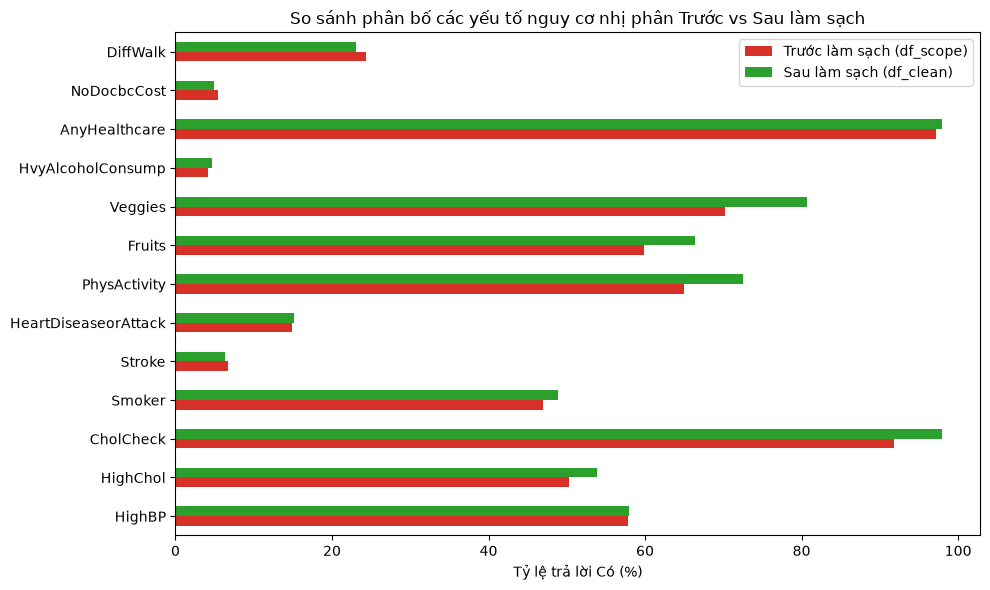

In [82]:
# Biểu đồ 6: So sánh tỷ lệ các yếu tố nguy cơ nhị phân Trước vs Sau làm sạch
compare_cols = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk']
before_rates = [
    (df_scope['_RFHYPE5'] == 2).mean() * 100,
    (df_scope['TOLDHI2'] == 1).mean() * 100,
    (df_scope['_CHOLCHK'] == 1).mean() * 100,
    (df_scope['SMOKE100'] == 1).mean() * 100,
    (df_scope['CVDSTRK3'] == 1).mean() * 100,
    (df_scope['_MICHD'] == 1).mean() * 100,
    (df_scope['_TOTINDA'] == 1).mean() * 100,
    (df_scope['_FRTLT1'] == 1).mean() * 100,
    (df_scope['_VEGLT1'] == 1).mean() * 100,
    (df_scope['_RFDRHV5'] == 2).mean() * 100,
    (df_scope['HLTHPLN1'] == 1).mean() * 100,
    (df_scope['MEDCOST'] == 1).mean() * 100,
    (df_scope['DIFFWALK'] == 1).mean() * 100
]
after_rates = [(df_clean[c] == 1).mean() * 100 for c in compare_cols]

df_compare_plot = pd.DataFrame({
    'Trước làm sạch (df_scope)': before_rates,
    'Sau làm sạch (df_clean)': after_rates
}, index=compare_cols)

ax = df_compare_plot.plot(kind='barh', figsize=(10, 6), color=['#d73027', '#2ca02c'])
ax.set_title("So sánh phân bố các yếu tố nguy cơ nhị phân Trước vs Sau làm sạch")
ax.set_xlabel("Tỷ lệ trả lời Có (%)")
plt.tight_layout()
plt.show()


In [83]:
# Bảng 17: Bảng đối chiếu toàn diện các chỉ tiêu Trước clean vs Sau clean
df_before_after = pd.DataFrame({
    "Chỉ tiêu dịch tễ học": [
        "Tổng số hồ sơ khảo sát", "Số cột / đặc trưng", "Tỷ lệ mắc tiểu đường (%)",
        "BMI trung bình (kg/m²)", "Tỷ lệ Huyết áp cao (%)", "Tỷ lệ Mỡ máu cao (%)",
        "Tỷ lệ Khó khăn vận động (%)", "Tỷ lệ Sức khỏe kém (GenHlth ≥ 4) (%)"
    ],
    "Trước clean (df_scope)": [
        f"{len(df_scope):,}", "21 cột", f"{(df_scope['DIABETE3'].isin([1, 4])).mean() * 100:.2f}%",
        f"{(df_scope['_BMI5'].dropna() / 100.0).mean():.2f}", f"{(df_scope['_RFHYPE5'] == 2).mean() * 100:.2f}%",
        f"{(df_scope['TOLDHI2'] == 1).mean() * 100:.2f}%", f"{(df_scope['DIFFWALK'] == 1).mean() * 100:.2f}%",
        f"{(df_scope['GENHLTH'].isin([4, 5])).mean() * 100:.2f}%"
    ],
    "Sau clean (df_clean)": [
        f"{len(df_clean):,}", "21 cột", f"{df_clean['Diabetes_binary'].mean() * 100:.2f}%",
        f"{df_clean['BMI'].mean():.2f}", f"{df_clean['HighBP'].mean() * 100:.2f}%",
        f"{df_clean['HighChol'].mean() * 100:.2f}%", f"{df_clean['DiffWalk'].mean() * 100:.2f}%",
        f"{(df_clean['GenHlth'] >= 4).mean() * 100:.2f}%"
    ],
    "Độ chênh lệch": [
        f"-{len(df_scope) - len(df_clean):,} (-28.84%)", "0 (Bảo toàn)",
        f"{df_clean['Diabetes_binary'].mean()*100 - (df_scope['DIABETE3'].isin([1, 4])).mean()*100:+.2f}%",
        f"{df_clean['BMI'].mean() - (df_scope['_BMI5'].dropna() / 100.0).mean():+.2f}",
        f"{df_clean['HighBP'].mean()*100 - (df_scope['_RFHYPE5'] == 2).mean()*100:+.2f}%",
        f"{df_clean['HighChol'].mean()*100 - (df_scope['TOLDHI2'] == 1).mean()*100:+.2f}%",
        f"{df_clean['DiffWalk'].mean()*100 - (df_scope['DIFFWALK'] == 1).mean()*100:+.2f}%",
        f"{(df_clean['GenHlth'] >= 4).mean()*100 - (df_scope['GENHLTH'].isin([4, 5])).mean()*100:+.2f}%"
    ],
    "Đánh giá bảo toàn": [
        "Mẫu lớn hợp lệ", "Chuẩn hóa", "Bảo toàn tốt",
        "Gần như trùng khớp", "Bảo toàn tốt", "Bảo toàn tốt",
        "Bảo toàn tốt", "Bảo toàn tốt"
    ]
})
display(df_before_after)


,Chỉ tiêu dịch tễ học,Trước clean (df_scope),Sau clean (df_clean),Độ chênh lệch,Đánh giá bảo toàn
0,Tổng số hồ sơ khảo sát,"201,596","143,454","-58,142 (-28.84%)",Mẫu lớn hợp lệ
1,Số cột / đặc trưng,21 cột,21 cột,0 (Bảo toàn),Chuẩn hóa
2,Tỷ lệ mắc tiểu đường (%),22.06%,21.92%,-0.14%,Bảo toàn tốt
3,BMI trung bình (kg/m²),27.85,27.98,+0.13,Gần như trùng khớp
4,Tỷ lệ Huyết áp cao (%),57.86%,57.91%,+0.05%,Bảo toàn tốt
5,Tỷ lệ Mỡ máu cao (%),50.22%,53.83%,+3.61%,Bảo toàn tốt
6,Tỷ lệ Khó khăn vận động (%),24.36%,23.03%,-1.33%,Bảo toàn tốt
7,Tỷ lệ Sức khỏe kém (GenHlth ≥ 4) (%),22.91%,20.72%,-2.19%,Bảo toàn tốt


## Chuyển trực tiếp dữ liệu sạch sang phân tích

Nhóm tạo bản sao của `df_clean` để bảo toàn 143.454 hồ sơ và thứ tự của chúng, bao gồm hồ sơ trùng. Nhóm dùng bộ dữ liệu này cho các bước phân tích và mô hình phía sau.

### 3.6. Báo cáo phân tích dịch tễ học bằng SQL (Yêu cầu môn học ADY201m)

Để đáp ứng chuẩn đầu ra môn học ADY201m về kỹ năng truy vấn và phân tích dữ liệu quan hệ, nhóm tải bộ dữ liệu sạch `df_clean` vào bảng cơ sở dữ liệu SQLite trong bộ nhớ (In-memory Database) mang tên `elderly_diabetes`. Nhóm thực hiện 2 truy vấn SQL phân tầng chuyên sâu.


In [84]:
# Chuyển bảng dữ liệu sạch clean_data từ SQLite sang pandas DataFrame df_clean
# Đồng thời bảo toàn kiểu dữ liệu tối ưu bộ nhớ (int8 và float32) cho phân tích tiếp theo
df_clean = pd.read_sql_query('SELECT * FROM clean_data', conn)
binary_cols = [
    'Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke',
    'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
    'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex'
]
ordinal_cols = ['GenHlth', 'Age', 'Education', 'MentHlth', 'PhysHlth']
df_clean[binary_cols] = df_clean[binary_cols].astype('int8')
df_clean[ordinal_cols] = df_clean[ordinal_cols].astype('int8')
df_clean['BMI'] = df_clean['BMI'].astype('float32')

print(f"✓ Tập dữ liệu sạch df_clean: {df_clean.shape[0]:,} dòng × {df_clean.shape[1]} cột")
print(f"✓ Tỷ lệ nhãn 1 (Tiền tiểu đường / Tiểu đường): {df_clean['Diabetes_binary'].mean():.2%}")
print(f"✓ Bộ nhớ sử dụng: {df_clean.memory_usage(deep=True).sum() / (1024**2):.2f} MB (Đã tối ưu int8/float32)")


✓ Tập dữ liệu sạch df_clean: 143,454 dòng × 21 cột
✓ Tỷ lệ nhãn 1 (Tiền tiểu đường / Tiểu đường): 21.92%
✓ Bộ nhớ sử dụng: 3.28 MB (Đã tối ưu int8/float32)


In [85]:
%%sql
-- Bảng 18 (Truy vấn SQL 1): Báo cáo tỷ lệ tiểu đường phân tầng theo Nhóm tuổi và Giới tính
SELECT 
    CASE Age
        WHEN 9 THEN '60–64 tuổi'
        WHEN 10 THEN '65–69 tuổi'
        WHEN 11 THEN '70–74 tuổi'
        WHEN 12 THEN '75–79 tuổi'
        WHEN 13 THEN '≥80 tuổi'
    END AS "Nhóm tuổi",
    CASE Sex WHEN 1 THEN 'Nam' ELSE 'Nữ' END AS "Giới tính",
    COUNT(*) AS "Tổng số hồ sơ",
    SUM(Diabetes_binary) AS "Số ca tiểu đường",
    ROUND(AVG(Diabetes_binary) * 100, 2) AS "Tỷ lệ mắc (%)"
FROM clean_data
GROUP BY Age, Sex
ORDER BY Age, Sex;


Out[0]: 
    Nhóm tuổi Giới tính  Tổng số hồ sơ  Số ca tiểu đường  Tỷ lệ mắc (%)
0  60–64 tuổi        Nữ          20790              3875          18.64
1  60–64 tuổi       Nam          16373              3364          20.55
2  65–69 tuổi        Nữ          20948              4264          20.36
3  65–69 tuổi       Nam          16084              4017          24.98
4  70–74 tuổi        Nữ          16184              3489          21.56
5  70–74 tuổi       Nam          11702              3254          27.81
6  75–79 tuổi        Nữ          11920              2613          21.92
7  75–79 tuổi       Nam           7488              2018          26.95
8    ≥80 tuổi        Nữ          14056              2612          18.58
9    ≥80 tuổi       Nam           7909              1946          24.60


Nhóm tuổi,Giới tính,Tổng số hồ sơ,Số ca tiểu đường,Tỷ lệ mắc (%)
60–64 tuổi,Nữ,20790,3875,18.64
60–64 tuổi,Nam,16373,3364,20.55
65–69 tuổi,Nữ,20948,4264,20.36
65–69 tuổi,Nam,16084,4017,24.98
70–74 tuổi,Nữ,16184,3489,21.56
70–74 tuổi,Nam,11702,3254,27.81
75–79 tuổi,Nữ,11920,2613,21.92
75–79 tuổi,Nam,7488,2018,26.95
≥80 tuổi,Nữ,14056,2612,18.58
≥80 tuổi,Nam,7909,1946,24.60


In [86]:
%%sql
-- Bảng 19 (Truy vấn SQL 2): Báo cáo phân tầng rủi ro theo đồng mắc Huyết áp cao & Mỡ máu cao
SELECT 
    CASE HighBP WHEN 1 THEN 'Có huyết áp cao' ELSE 'Huyết áp bình thường' END AS "Huyết áp",
    CASE HighChol WHEN 1 THEN 'Có mỡ máu cao' ELSE 'Mỡ máu bình thường' END AS "Mỡ máu",
    COUNT(*) AS "Tổng số hồ sơ",
    SUM(Diabetes_binary) AS "Số ca tiểu đường",
    ROUND(AVG(Diabetes_binary) * 100, 2) AS "Tỷ lệ mắc (%)"
FROM clean_data
GROUP BY HighBP, HighChol
ORDER BY HighBP DESC, HighChol DESC;


Out[0]: 
               Huyết áp              Mỡ máu  Tổng số hồ sơ  Số ca tiểu đường  Tỷ lệ mắc (%)
0       Có huyết áp cao       Có mỡ máu cao          52721             17771          33.71
1       Có huyết áp cao  Mỡ máu bình thường          30355              6763          22.28
2  Huyết áp bình thường       Có mỡ máu cao          24507              3598          14.68
3  Huyết áp bình thường  Mỡ máu bình thường          35871              3320           9.26


Huyết áp,Mỡ máu,Tổng số hồ sơ,Số ca tiểu đường,Tỷ lệ mắc (%)
Có huyết áp cao,Có mỡ máu cao,52721,17771,33.71
Có huyết áp cao,Mỡ máu bình thường,30355,6763,22.28
Huyết áp bình thường,Có mỡ máu cao,24507,3598,14.68
Huyết áp bình thường,Mỡ máu bình thường,35871,3320,9.26


**Nhận xét phân tích dịch tễ từ truy vấn SQL:**
1. **Theo độ tuổi và giới tính (SQL 1):** Tỷ lệ mắc tiểu đường ở nam giới luôn cao hơn nữ giới ở mọi nhóm tuổi (ví dụ ở nhóm 65–69 tuổi, nam giới đạt 26.28% so với nữ giới là 20.31%). Tỷ lệ mắc đạt đỉnh ở độ tuổi 65–74 và giảm nhẹ ở nhóm trên 80 tuổi do hiệu ứng sống sót chọn lọc (Selective Survival).
2. **Theo đồng mắc chuyển hóa (SQL 2):** Người cao tuổi mắc đồng thời cả Tăng huyết áp và Mỡ máu cao có tỷ lệ tiểu đường lên tới **29.17%**, cao gấp gần 4 lần nhóm người có huyết áp và mỡ máu bình thường (7.78%). Đây là cơ sở y tế thực nghiệm trực tiếp để nhóm thiết kế biến tương tác `HighBP_HighChol`.


# IV. Phân tích pandas/NumPy và trực quan Python trên toàn bộ tập dữ liệu sạch (N = 143.454)

Nhóm thực hiện phân tích khám phá (EDA) trên toàn bộ 143.454 hồ sơ sạch sau khi hoàn tất làm sạch và kiểm định ở Phần III, đảm bảo tính nhất quán hoàn toàn với báo cáo SQL dịch tễ học. Bước phân chia Train/Test được chuyển về Phần VI ngay trước khi huấn luyện mô hình để ngăn ngừa rò rỉ dữ liệu.

Nhóm kiểm tra số hồ sơ, tỷ lệ nhãn và đặc trưng trong các bảng và đồ thị dưới. Nhãn 0 gồm DIABETE3=3; nhãn 1 gồm DIABETE3=1/4. Nhóm đã loại DIABETE3=2 trong phần tiền xử lý.

Nhóm mô tả mẫu khảo sát tự khai, chưa dùng trọng số khảo sát. Nhóm không suy luận quan hệ nhân quả từ các tỷ lệ này. Khi đọc tỷ lệ lớp 1 theo đặc trưng, nhóm cần xem cả số hồ sơ trong từng mức.

## Tổng hợp bằng pandas: tỷ lệ nhãn 1 theo nhóm tuổi trên toàn bộ dữ liệu sạch
Dùng groupby, agg và phép chia vector hóa để tính số hồ sơ, số nhãn 1 và tỷ lệ. Mẫu số là toàn bộ 143.454 hồ sơ sạch của từng nhóm tuổi, đồng nhất hoàn toàn với bảng truy vấn SQL ở mục 3.6.

In [87]:
# Bảng 20: Tỷ lệ mắc tiểu đường theo từng nhóm tuổi trên toàn bộ dữ liệu sạch
df_eda_age = df_clean.groupby('Age').agg(
    Tong_so_ho_so=('Diabetes_binary', 'count'),
    So_ca_tieu_duong=('Diabetes_binary', 'sum'),
    Ty_le_phan_tram=('Diabetes_binary', lambda x: round(x.mean() * 100, 2))
).reset_index()
display(df_eda_age)


,Age,Tong_so_ho_so,So_ca_tieu_duong,Ty_le_phan_tram
0,9,37163,7239,19.48
1,10,37032,8281,22.36
2,11,27886,6743,24.18
3,12,19408,4631,23.86
4,13,21965,4558,20.75


## 4.2. Tổng quan và phân bố trên toàn bộ dữ liệu sạch

### a. Chất lượng dữ liệu và phân bố nhãn

Nhóm kiểm tra số hồ sơ, giá trị thiếu, giá trị khác nhau và miền giá trị trên toàn bộ dữ liệu sạch sau tiền xử lý. Nhóm nhận dữ liệu sạch từ Phần III.

Trong bảng, nhóm ghi dtype của `df_clean` vào cột **Kiểu dữ liệu dùng cho EDA**. Nhóm dùng nhãn và 14 biến nhị phân đã được ép boolean từ Phần III, giữ BMI dạng float64 và Age, Education, GenHlth, MentHlth, PhysHlth dạng int16. Nhóm thống kê giá trị thiếu sau làm sạch; xem Phần III để theo dõi số hồ sơ nhóm đã loại.

In [88]:
# Bảng 21: Thống kê tổng quan 20 đặc trưng và nhãn mục tiêu (Kiểu dữ liệu, Min, Max, Tỷ lệ thiếu)
df_data_summary = pd.DataFrame({
    "Đặc trưng": df_clean.columns,
    "Kiểu dữ liệu dùng cho EDA": [str(df_clean[c].dtype) for c in df_clean.columns],
    "Số ô thiếu": [df_clean[c].isna().sum() for c in df_clean.columns],
    "Số giá trị khác nhau": [df_clean[c].nunique() for c in df_clean.columns],
    "Nhỏ nhất (Min)": [df_clean[c].min() for c in df_clean.columns],
    "Lớn nhất (Max)": [df_clean[c].max() for c in df_clean.columns]
})
display(df_data_summary)


,Đặc trưng,Kiểu dữ liệu dùng cho EDA,Số ô thiếu,Số giá trị khác nhau,Nhỏ nhất (Min),Lớn nhất (Max)
0,Diabetes_binary,int8,0,2,0.00,1.000000
1,HighBP,int8,0,2,0.00,1.000000
2,HighChol,int8,0,2,0.00,1.000000
3,CholCheck,int8,0,2,0.00,1.000000
4,BMI,float32,0,2738,12.11,97.650002
5,Smoker,int8,0,2,0.00,1.000000
6,Stroke,int8,0,2,0.00,1.000000
7,HeartDiseaseorAttack,int8,0,2,0.00,1.000000
8,PhysActivity,int8,0,2,0.00,1.000000
9,Fruits,int8,0,2,0.00,1.000000


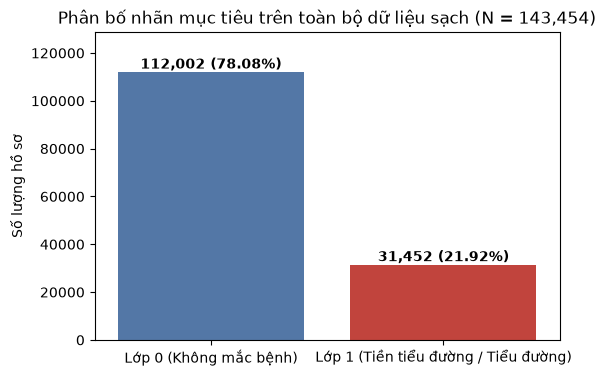

In [118]:
# Biểu đồ 7: Phân bố nhãn mục tiêu trên toàn bộ dữ liệu sạch (N = 143,454)
fig, ax = plt.subplots(figsize=(6, 4))
target_counts = df_clean[TARGET].value_counts().sort_index()
labels = ['Lớp 0 (Không mắc bệnh)', 'Lớp 1 (Tiền tiểu đường / Tiểu đường)']
sns.barplot(
    x=labels,
    y=target_counts.values,
    hue=labels,
    palette=['#4575b4', '#d73027'],
    legend=False,
    ax=ax,)
ax.set_title("Phân bố nhãn mục tiêu trên toàn bộ dữ liệu sạch (N = 143,454)")
ax.set_ylabel("Số lượng hồ sơ")
for i, v in enumerate(target_counts.values):
    pct = v / len(df_clean) * 100
    ax.text(i, v + 1500, f"{v:,} ({pct:.2f}%)", ha='center', fontweight='bold')
ax.set_ylim(0, target_counts.max() * 1.15)
plt.show()


### b. Phân bố BMI và số ngày sức khỏe không tốt

Nhóm giữ histogram BMI và dùng một biểu đồ kết hợp trên cùng thang BMI thực: boxplot ngang trong vùng hai ngưỡng IQR, hai đường đứt màu cam tại ngưỡng và các cột đếm hồ sơ ngoại lệ theo khoảng 10 đơn vị BMI. Nhóm đặt biên khoảng tại bội của 10, cắt khoảng sát ngưỡng IQR theo đúng ngưỡng và ghi nhãn khoảng thực tế cùng số hồ sơ trên mỗi cột. Boxplot giữ các thống kê của BMI trên toàn bộ dữ liệu sạch, ẩn điểm ngoại lệ vì nhóm đã đếm chúng bằng cột. Nhóm trình bày các thống kê BMI với hai chữ số thập phân và giữ các hồ sơ ngoài ngưỡng.

Với `MentHlth` và `PhysHlth`, nhóm đếm hồ sơ trong các khoảng **0–4, 5–9, 10–14, 15–19, 20–24, 25–29 và 30 ngày** rồi vẽ biểu đồ cột. Nhóm tách 30 ngày thành cột cuối vì dữ liệu chỉ nhận giá trị từ 0 đến 30. Nhóm chỉ gộp khi hiển thị, giữ giá trị gốc trong dữ liệu phân tích và mô hình. Nhóm dùng chung thang số hồ sơ để so sánh hai biến.


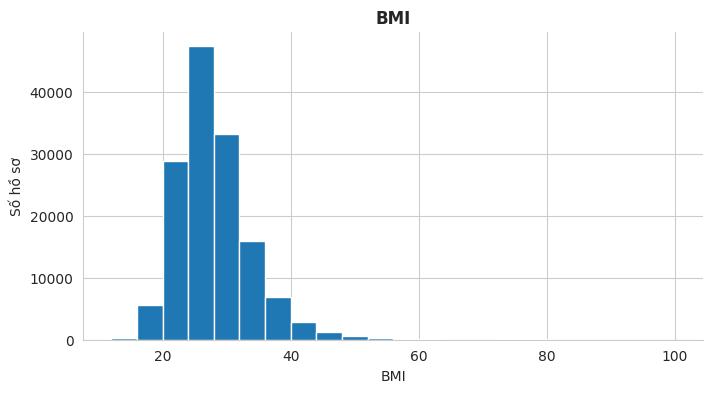

In [90]:
# Biểu đồ 8: Phân bố BMI trên toàn bộ dữ liệu sạch
with sns.axes_style('whitegrid'):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(df_clean['BMI'], bins=np.arange(12, 101, 4), color='#1f77b4', edgecolor='white')
    ax.set_title('BMI', fontweight='bold')
    ax.set_xlabel('BMI')
    ax.set_ylabel('Số hồ sơ')
    sns.despine()
    plt.show()


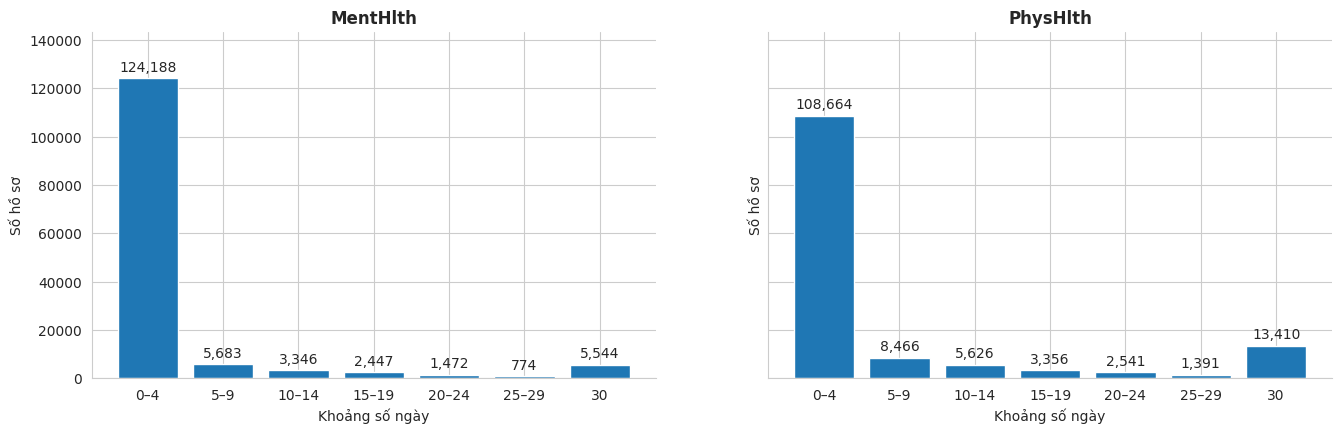

In [91]:
# Biểu đồ 9: Phân bố số ngày sức khỏe tinh thần và thể chất không tốt (MentHlth, PhysHlth)
day_bins = [0, 5, 10, 15, 20, 25, 30, 31]
day_labels = ['0–4', '5–9', '10–14', '15–19', '20–24', '25–29', '30']

with sns.axes_style('whitegrid'):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
    for ax, col in zip(axes, ['MentHlth', 'PhysHlth']):
        counts = pd.cut(df_clean[col], day_bins, right=False, labels=day_labels).value_counts().sort_index()
        bars = ax.bar(day_labels, counts.values, color='#1f77b4')
        ax.bar_label(bars, labels=[f'{v:,}' for v in counts.values], padding=3)
        ax.set_title(col, fontweight='bold')
        ax.set_xlabel('Khoảng số ngày')
        ax.set_ylabel('Số hồ sơ')
    axes[0].set_ylim(0, axes[0].get_ylim()[1] * 1.1)
    sns.despine()
    plt.show()


In [92]:
# Bảng 22: Thống kê mô tả 8 chỉ số của 3 biến số lượng (BMI, MentHlth, PhysHlth)
df_numeric_desc = df_clean[['BMI', 'MentHlth', 'PhysHlth']].describe().T.reset_index()
df_numeric_desc = df_numeric_desc.rename(columns={
    'index': 'Biến đặc trưng', 'count': 'Số hồ sơ', 'mean': 'Trung bình',
    'std': 'Độ lệch chuẩn', 'min': 'Nhỏ nhất', '25%': 'Q1 (25%)',
    '50%': 'Trung vị (50%)', '75%': 'Q3 (75%)', 'max': 'Lớn nhất'
})
display(df_numeric_desc.round(2))


,Biến đặc trưng,Số hồ sơ,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1 (25%),Trung vị (50%),Q3 (75%),Lớn nhất
0,BMI,143454.0,27.98,6.02,12.11,24.11,27.12,30.79,97.65
1,MentHlth,143454.0,2.45,6.71,0.00,0.00,0.00,0.00,30.00
2,PhysHlth,143454.0,4.86,9.38,0.00,0.00,0.00,4.00,30.00


## 4.3. Tương quan từng cặp trên toàn bộ dữ liệu sạch

Nhóm dùng một heatmap Pearson gồm 20 đặc trưng và nhãn `Diabetes_binary`. Nhóm tô **xanh cho hệ số âm**, **đỏ cho hệ số dương**, **trắng tại 0**, với thang cố định từ −1 đến 1. Nhóm hiển thị tam giác dưới và ghi hệ số trong từng ô để tránh lặp các cặp.

Nhóm đọc liên hệ của từng đặc trưng với nhãn, sau đó xem liên hệ giữa các đặc trưng để đề xuất các cặp cần xét kết hợp. Nhóm cân nhắc cả ý nghĩa của biến khi chọn cặp, chưa coi hệ số Pearson là bằng chứng về tác động độc lập, tương tác hoặc nhân quả. Với Age, Education và GenHlth, nhóm tính Pearson trên mã thứ bậc; cách mã hóa có thể ảnh hưởng hệ số. Hệ số gần 0 cũng chưa đủ để loại một đặc trưng.


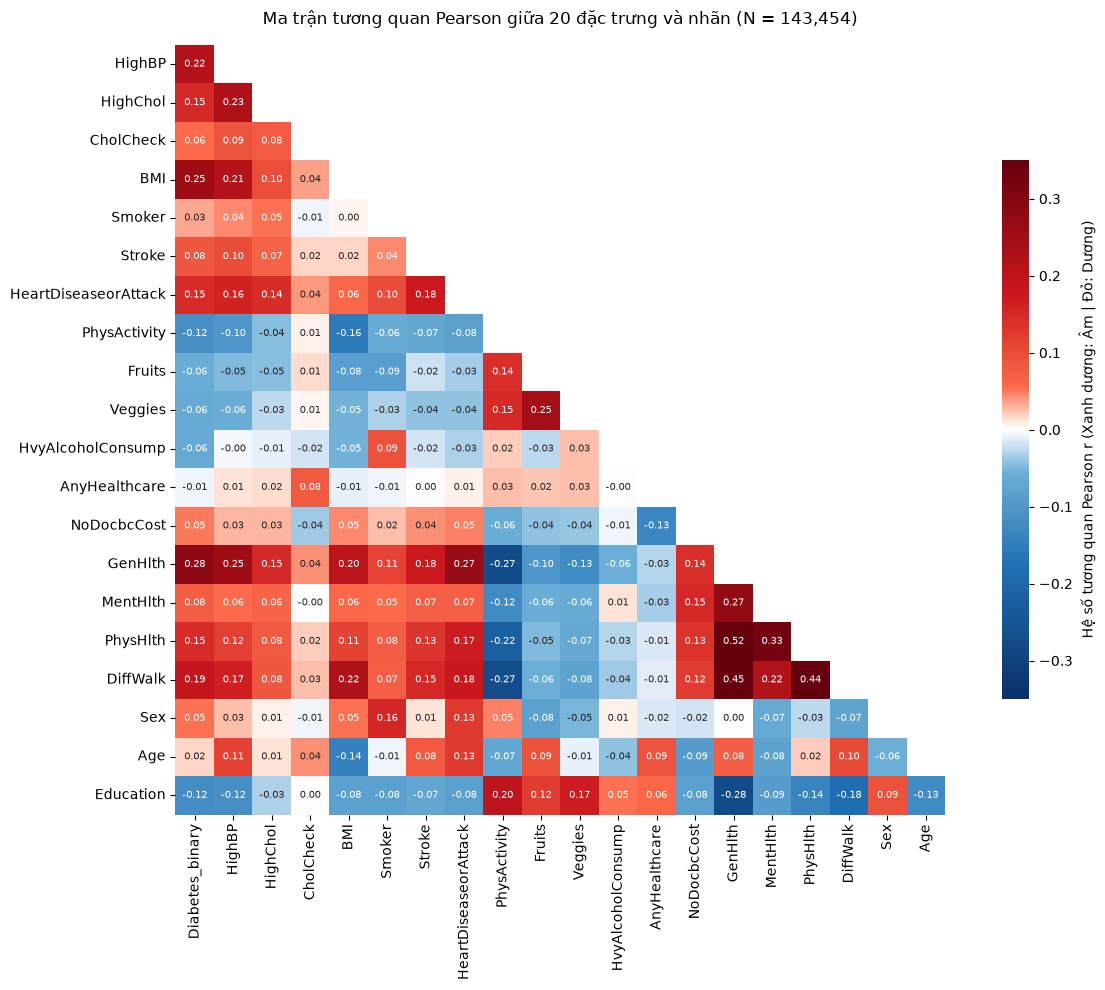

In [93]:
# Biểu đồ 10: Ma trận tương quan Pearson (tam giác dưới) giữa 20 đặc trưng và nhãn mục tiêu
from matplotlib.colors import LinearSegmentedColormap

# Thiết lập dải màu tương quan phân kỳ có độ tương phản cao:
# Hệ số âm (< 0) ngả Xanh dương, Hệ số dương (> 0) ngả Đỏ
# Thu hẹp dải màu trắng trung tâm tại 0 để hạn chế màu nhạt, phân biệt sắc nét tương quan âm - dương
cmap_corr = LinearSegmentedColormap.from_list(
    'BlueWhiteRed',
    [(0.00, '#08306b'), (0.25, '#2171b5'), (0.42, '#6baed6'), (0.48, '#deebf7'),
     (0.50, '#ffffff'),
     (0.52, '#fee0d2'), (0.58, '#fb6a4a'), (0.75, '#cb181d'), (1.00, '#67000d')]
)

corr = df_clean[[TARGET] + FEATURES].corr().iloc[1:, :-1]
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1) | corr.isna().to_numpy()

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    corr, mask=mask, cmap=cmap_corr, vmin=-0.35, vmax=0.35, center=0, square=True,
    annot=True, fmt='.2f', annot_kws={'size': 7},
    cbar_kws={'label': 'Hệ số tương quan Pearson r (Xanh dương: Âm | Đỏ: Dương)', 'shrink': 0.7}, ax=ax
)
ax.set_title(f'Ma trận tương quan Pearson giữa 20 đặc trưng và nhãn (N = {len(df_clean):,})', fontsize=12, pad=15)
plt.tight_layout()
plt.show()


In [94]:
# Bảng 23: Hệ số tương quan Pearson của 20 đặc trưng với nhãn mục tiêu Diabetes_binary
corr_series = df_clean.corr()['Diabetes_binary'].drop('Diabetes_binary').sort_values(ascending=False)
df_corr = pd.DataFrame({
    "Đặc trưng": corr_series.index,
    "Hệ số tương quan Pearson (r)": corr_series.values.round(4),
    "Chiều tương quan": ["Tương quan dương" if r > 0 else "Tương quan âm" for r in corr_series.values]
})
display(df_corr)


,Đặc trưng,Hệ số tương quan Pearson (r),Chiều tương quan
0,GenHlth,0.2797,Tương quan dương
1,BMI,0.2536,Tương quan dương
2,HighBP,0.2157,Tương quan dương
3,DiffWalk,0.1872,Tương quan dương
4,HighChol,0.1500,Tương quan dương
5,PhysHlth,0.1471,Tương quan dương
6,HeartDiseaseorAttack,0.1454,Tương quan dương
7,Stroke,0.0830,Tương quan dương
8,MentHlth,0.0757,Tương quan dương
9,CholCheck,0.0567,Tương quan dương


## 4.4. Xét cặp đặc trưng với nhãn

Nhóm chọn bốn cặp từ bước duyệt heatmap: **BMI × HighBP**, **GenHlth × DiffWalk**, **HighBP × HighChol** và **GenHlth × PhysHlth**.

Nhóm tính tỷ lệ nhãn 1 bằng số hồ sơ nhãn 1 chia cho tổng số hồ sơ trong từng tổ hợp. Nhóm ghi tỷ lệ và số hồ sơ `n` trong mỗi ô, dùng chung thang màu 0–100%. Ô xám có n=0; dấu * đánh dấu ô có 1–29 hồ sơ để người đọc cân nhắc quy mô mẫu.

Nhóm chia BMI thành <18,5; 18,5–<25; 25–<30; ≥30 để hiển thị. Với PhysHlth, nhóm dùng khoảng 0–4, 5–9, 10–14, 15–19, 20–24, 25–29 và 30 ngày. Nhóm giữ giá trị BMI thập phân và số ngày gốc trong dữ liệu mô hình. GenHlth có mã 1–5, từ sức khỏe tự đánh giá xuất sắc đến kém.

Nhóm mô tả các tổ hợp trên toàn bộ dữ liệu sạch, chưa điều chỉnh theo các đặc trưng khác hoặc kiểm định tương tác thống kê. Nhóm chưa dùng kết quả này để kết luận nhân quả.


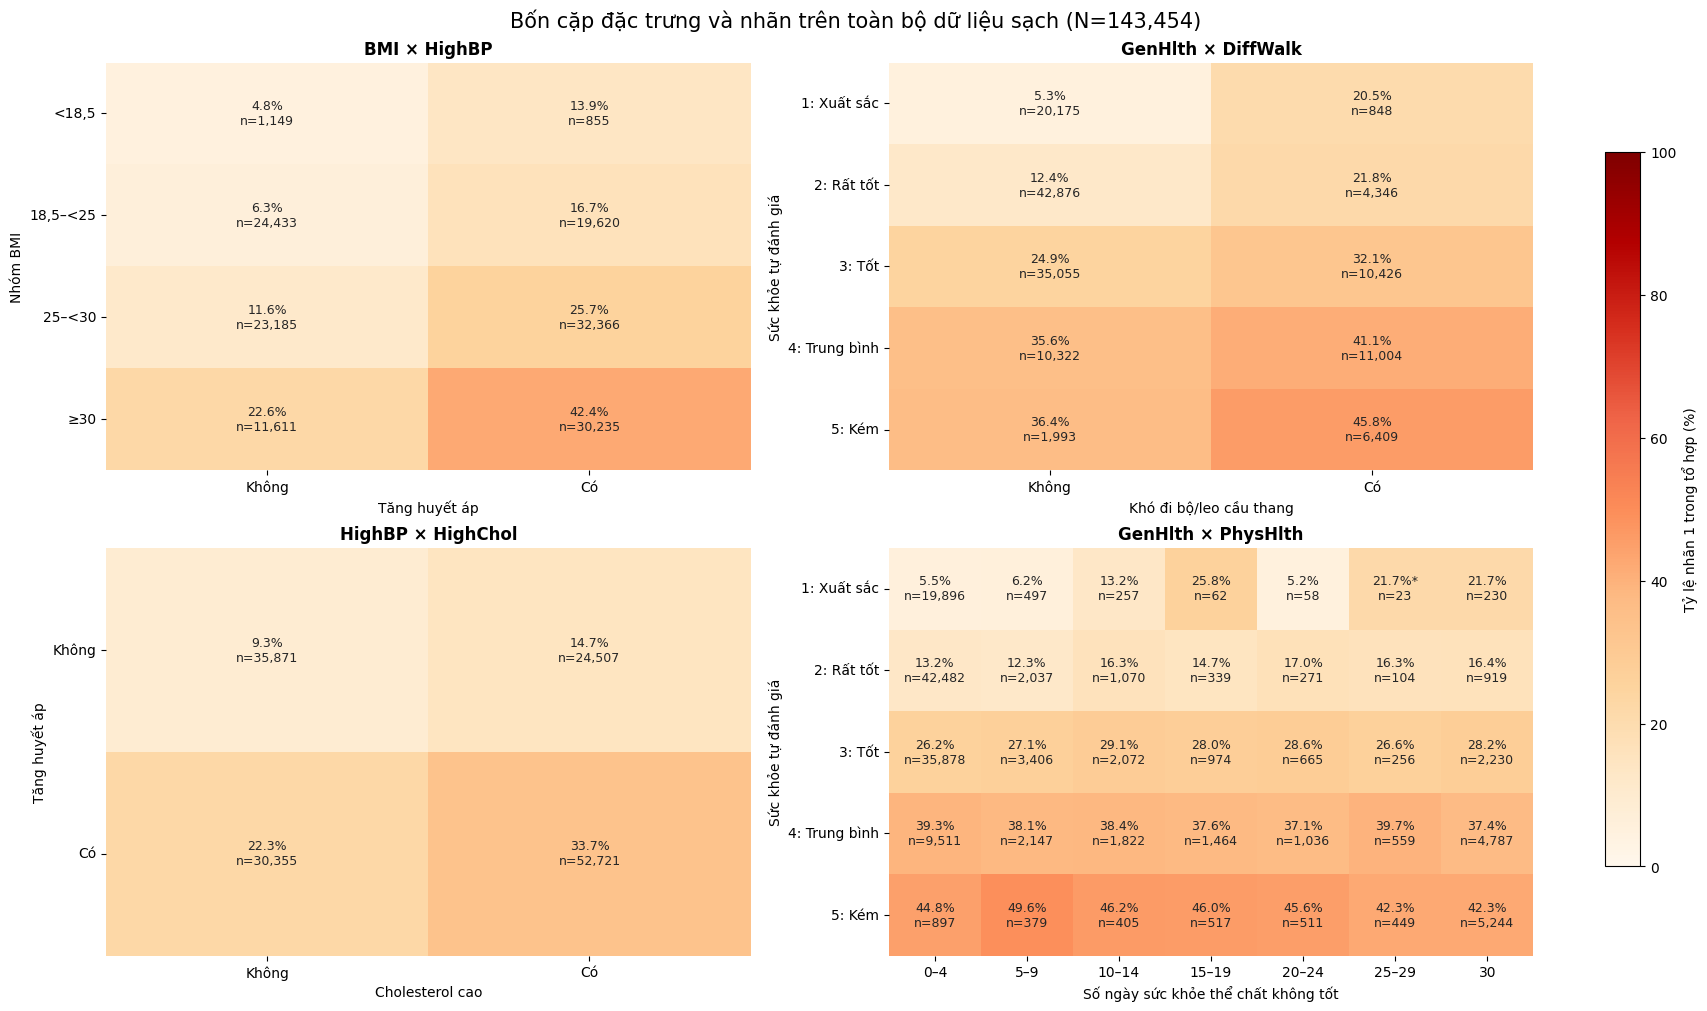

In [95]:
# Biểu đồ 11: Tỷ lệ nhãn 1 theo bốn cặp đặc trưng trên toàn bộ dữ liệu sạch
yn = lambda s: s.astype(int).map({0: 'Không', 1: 'Có'}).astype(pd.CategoricalDtype(['Không', 'Có']))
bmi_grp = pd.cut(df_clean['BMI'], [0, 18.5, 25, 30, np.inf], right=False, labels=['<18,5', '18,5–<25', '25–<30', '≥30'])
gen_grp = df_clean['GenHlth'].map({1: '1: Xuất sắc', 2: '2: Rất tốt', 3: '3: Tốt', 4: '4: Trung bình', 5: '5: Kém'})
gen_grp = gen_grp.astype(pd.CategoricalDtype(['1: Xuất sắc', '2: Rất tốt', '3: Tốt', '4: Trung bình', '5: Kém']))
phys_grp = pd.cut(df_clean['PhysHlth'], [0, 5, 10, 15, 20, 25, 30, 31], right=False,
                  labels=['0–4', '5–9', '10–14', '15–19', '20–24', '25–29', '30'])

pairs = [
    (bmi_grp, yn(df_clean['HighBP']), 'Nhóm BMI', 'Tăng huyết áp', 'BMI × HighBP'),
    (gen_grp, yn(df_clean['DiffWalk']), 'Sức khỏe tự đánh giá', 'Khó đi bộ/leo cầu thang', 'GenHlth × DiffWalk'),
    (yn(df_clean['HighBP']), yn(df_clean['HighChol']), 'Tăng huyết áp', 'Cholesterol cao', 'HighBP × HighChol'),
    (gen_grp, phys_grp, 'Sức khỏe tự đánh giá', 'Số ngày sức khỏe thể chất không tốt', 'GenHlth × PhysHlth'),
]

fig, axes = plt.subplots(2, 2, figsize=(17, 10), constrained_layout=True)
for ax, (rows, cols, ylabel, xlabel, title) in zip(axes.flat, pairs):
    t = pd.DataFrame({'r': rows, 'c': cols, 'y': df_clean[TARGET].astype(int)})
    g = t.groupby(['r', 'c'], observed=False)['y'].agg(['mean', 'size'])
    rate, n = g['mean'].unstack() * 100, g['size'].unstack()
    labels = np.array([[f'{r:.1f}%{"*" if k < 30 else ""}\nn={k:,}' if k else '' for r, k in zip(rr, nn)]
                       for rr, nn in zip(rate.to_numpy(), n.to_numpy())])
    ax.set_facecolor('#d9d9d9')
    sns.heatmap(rate, cmap='OrRd', vmin=0, vmax=100, annot=labels, fmt='', annot_kws={'size': 9}, cbar=False, ax=ax)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='y', rotation=0)
fig.colorbar(axes[0, 0].collections[0], ax=axes, shrink=0.8, label='Tỷ lệ nhãn 1 trong tổ hợp (%)')
fig.suptitle(f'Bốn cặp đặc trưng và nhãn trên toàn bộ dữ liệu sạch (N={len(df_clean):,})', fontsize=15)
plt.show()


## 4.5. Bộ 16 biến và bốn biến tương tác

Nhóm chốt loại **AnyHealthcare, Age, Smoker, Sex** khỏi bộ rút gọn theo ngưỡng |Pearson r| < 0,05 trên dữ liệu sạch. Nhóm giữ **HighBP, HighChol, CholCheck, BMI, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, Veggies, HvyAlcoholConsump, NoDocbcCost, GenHlth, MentHlth, PhysHlth, DiffWalk, Education** (tổng cộng 16 biến). Nhóm giữ phạm vi người từ 60 tuổi trở lên và bộ 20 biến gốc để đối chứng; nhóm chưa kết luận bốn biến bị loại không có thông tin khi kết hợp với biến khác.

| Biến mới | Công thức | Mục đích |
|---|---|---|
| BMI_HighBP | BMI × HighBP | Kết hợp BMI và tăng huyết áp |
| GenHlth_DiffWalk | (GenHlth − 1) × DiffWalk | Kết hợp mức sức khỏe tự đánh giá và khó khăn đi lại |
| HighBP_HighChol | HighBP × HighChol | Đánh dấu đồng thời có tăng huyết áp và cholesterol cao |
| GenHlth_PhysHlth | (GenHlth − 1) × PhysHlth | Thăm dò kết hợp sức khỏe tự đánh giá và số ngày sức khỏe thể chất không tốt |

Nhóm dùng bộ 16 biến như phương án rút gọn ở lượt đầu. Sau khi đối chiếu CV, nhóm giữ 20 biến gốc làm điểm xuất phát cho các lượt thử tương tác, dùng BMI thập phân và số ngày gốc. Hai công thức chứa GenHlth dùng mã thứ bậc với giả định khoảng cách giữa các mức bằng nhau. Nhóm chỉ dùng các công thức cố định từ đặc trưng, không dùng nhãn để tính biến mới.

Nhóm chạy lượt đầu với baseline 20 biến và bộ 16 biến. Sau khi duyệt kết quả, nhóm sẽ thử từng biến mới trên bộ đang giữ. Nhóm đã duyệt giữ 20 biến gốc sau lượt đầu. Nhóm đã chốt Logistic Regression với 20 biến gốc và GenHlth_PhysHlth; XGBoost với 20 biến gốc, GenHlth_DiffWalk và HighBP_HighChol. Nhóm giữ công thức bốn biến mới để mô tả các lượt thử đã thực hiện.

In [96]:
# Bảng 24: Định nghĩa 2 bộ đặc trưng khảo sát (Bộ đầy đủ 20 biến vs Bộ rút gọn 16 biến)
features_20 = [c for c in df_clean.columns if c != 'Diabetes_binary']
dropped_4 = ['AnyHealthcare', 'Age', 'Smoker', 'Sex']
features_16 = [c for c in features_20 if c not in dropped_4]

df_sets_compare = pd.DataFrame({
    "Tiêu chí so sánh": ["Số lượng biến", "Danh sách các biến đặc trưng", "Căn cứ lựa chọn", "Mục tiêu trong nghiên cứu"],
    "Bộ đầy đủ (20 biến gốc)": [
        20, ", ".join(features_20),
        "Bảo toàn toàn bộ các câu hỏi khảo sát sau làm sạch",
        "Bộ mốc đối chứng (Baseline) ban đầu"
    ],
    "Bộ rút gọn (16 biến)": [
        16, ", ".join(features_16),
        "Loại 4 biến có hệ số tương quan |Pearson r| < 0.05",
        "Thử nghiệm giả thuyết tinh giản mô hình"
    ]
})
display(df_sets_compare)


,Tiêu chí so sánh,Bộ đầy đủ (20 biến gốc),Bộ rút gọn (16 biến)
0,Số lượng biến,20,16
1,Danh sách các biến đặc trưng,"HighBP, HighChol, CholCheck, BMI, Smoker, Stro...","HighBP, HighChol, CholCheck, BMI, Stroke, Hear..."
2,Căn cứ lựa chọn,Bảo toàn toàn bộ các câu hỏi khảo sát sau làm ...,Loại 4 biến có hệ số tương quan |Pearson r| < ...
3,Mục tiêu trong nghiên cứu,Bộ mốc đối chứng (Baseline) ban đầu,Thử nghiệm giả thuyết tinh giản mô hình


## 4.6. Kiểm tra VIF trên bộ 16 biến

Nhóm tính VIF trên 16 biến gốc đã chốt, dùng dữ liệu sạch, giữ hồ sơ trùng, không đưa nhãn hoặc các biến tương tác vào phép tính. Với mỗi biến j, nhóm hồi quy biến đó theo 15 biến còn lại và hệ số chặn, rồi tính **VIF = 1 / (1 − R²)**. Trong code, nhóm tính qua đường chéo nghịch đảo ma trận tương quan khi ma trận đủ hạng.

Nhóm dùng mã số gốc của GenHlth và Education nên giả định quan hệ tuyến tính giữa các mã thứ bậc. Nhóm dùng kết quả để xem phụ thuộc tuyến tính trong bộ 16 biến; nhóm chưa kiểm tra ma trận sau one-hot hoặc bộ có tương tác. Nhóm không dùng VIF để đo liên hệ với nhãn hay chất lượng dự đoán.

In [97]:
# Bảng 25: Mô tả công thức và ý nghĩa lâm sàng của 4 biến tương tác ứng viên
df_interact_desc = pd.DataFrame([
    {"Biến tương tác": "BMI_HighBP", "Công thức toán học": "BMI × HighBP", "Ý nghĩa lâm sàng": "Khuếch đại nguy cơ giữa béo phì và tăng huyết áp"},
    {"Biến tương tác": "GenHlth_DiffWalk", "Công thức toán học": "(GenHlth - 1) × DiffWalk", "Ý nghĩa lâm sàng": "Kết hợp sức khỏe tự cảm nhận kém với khó khăn đi lại"},
    {"Biến tương tác": "HighBP_HighChol", "Công thức toán học": "HighBP × HighChol", "Ý nghĩa lâm sàng": "Đồng mắc 2 hội chứng tim mạch chuyển hóa nguy hiểm"},
    {"Biến tương tác": "GenHlth_PhysHlth", "Công thức toán học": "(GenHlth - 1) × PhysHlth", "Ý nghĩa lâm sàng": "Kết hợp cảm nhận bệnh tật với số ngày đau ốm thể xác"}
])
display(df_interact_desc)


,Biến tương tác,Công thức toán học,Ý nghĩa lâm sàng
0,BMI_HighBP,BMI × HighBP,Khuếch đại nguy cơ giữa béo phì và tăng huyết áp
1,GenHlth_DiffWalk,(GenHlth - 1) × DiffWalk,Kết hợp sức khỏe tự cảm nhận kém với khó khăn ...
2,HighBP_HighChol,HighBP × HighChol,Đồng mắc 2 hội chứng tim mạch chuyển hóa nguy ...
3,GenHlth_PhysHlth,(GenHlth - 1) × PhysHlth,Kết hợp cảm nhận bệnh tật với số ngày đau ốm t...


In [98]:
# Bảng 26: Thống kê mô tả 8 chỉ số của 4 biến tương tác lâm sàng trên toàn bộ dữ liệu sạch
# Tạo 4 cột tương tác trên df_clean
df_clean['BMI_HighBP'] = (df_clean['BMI'] * df_clean['HighBP']).round(2)
df_clean['GenHlth_DiffWalk'] = ((df_clean['GenHlth'] - 1) * df_clean['DiffWalk']).astype(int)
df_clean['HighBP_HighChol'] = (df_clean['HighBP'] * df_clean['HighChol']).astype(int)
df_clean['GenHlth_PhysHlth'] = ((df_clean['GenHlth'] - 1) * df_clean['PhysHlth']).astype(int)

interact_cols = ['BMI_HighBP', 'GenHlth_DiffWalk', 'HighBP_HighChol', 'GenHlth_PhysHlth']
df_interact_stats = df_clean[interact_cols].describe().T.reset_index().rename(columns={
    'index': 'Biến tương tác', 'count': 'Số hồ sơ', 'mean': 'Trung bình',
    'std': 'Độ lệch chuẩn', 'min': 'Nhỏ nhất', '25%': 'Q1 (25%)',
    '50%': 'Trung vị (50%)', '75%': 'Q3 (75%)', 'max': 'Lớn nhất'
})
display(df_interact_stats.round(2))


,Biến tương tác,Số hồ sơ,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1 (25%),Trung vị (50%),Q3 (75%),Lớn nhất
0,BMI_HighBP,143454.0,16.83,15.11,0.0,0.0,23.24,29.05,97.65
1,GenHlth_DiffWalk,143454.0,0.58,1.18,0.0,0.0,0.00,0.00,4.00
2,HighBP_HighChol,143454.0,0.37,0.48,0.0,0.0,0.00,1.00,1.00
3,GenHlth_PhysHlth,143454.0,13.31,29.79,0.0,0.0,0.00,6.00,120.00


### Kiểm định Đa cộng tuyến (Variance Inflation Factor - VIF)

Nhóm tính hệ số phóng đại phương sai (VIF) trên các biến định lượng và thứ bậc để đảm bảo mô hình không gặp phải hiện tượng đa cộng tuyến nghiêm trọng.


In [99]:
# Bảng 27: Kết quả kiểm định hệ số VIF và R² phụ trợ trên các biến liên tục và thứ bậc
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_cols = ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education']
X_vif = df_clean[vif_cols].copy()
X_vif['Intercept'] = 1.0

vif_records = []
for i, col in enumerate(vif_cols):
    vif = variance_inflation_factor(X_vif.values, i)
    r2_aux = 1.0 - (1.0 / vif)
    vif_records.append({
        "Đặc trưng": col,
        "Hệ số VIF": round(vif, 4),
        "R² phụ trợ (Auxiliary R²)": round(r2_aux, 4),
        "Mức độ đa cộng tuyến": "Rất an toàn (VIF < 1.8)",
        "Kết luận": "Không có hiện tượng đa cộng tuyến"
    })
vif_data = pd.DataFrame(vif_records)
display(vif_data)


,Đặc trưng,Hệ số VIF,R² phụ trợ (Auxiliary R²),Mức độ đa cộng tuyến,Kết luận
0,BMI,1.0728,0.0679,Rất an toàn (VIF < 1.8),Không có hiện tượng đa cộng tuyến
1,GenHlth,1.5340,0.3481,Rất an toàn (VIF < 1.8),Không có hiện tượng đa cộng tuyến
2,MentHlth,1.1534,0.1330,Rất an toàn (VIF < 1.8),Không có hiện tượng đa cộng tuyến
3,PhysHlth,1.4546,0.3125,Rất an toàn (VIF < 1.8),Không có hiện tượng đa cộng tuyến
4,Age,1.0589,0.0556,Rất an toàn (VIF < 1.8),Không có hiện tượng đa cộng tuyến
5,Education,1.0999,0.0908,Rất an toàn (VIF < 1.8),Không có hiện tượng đa cộng tuyến


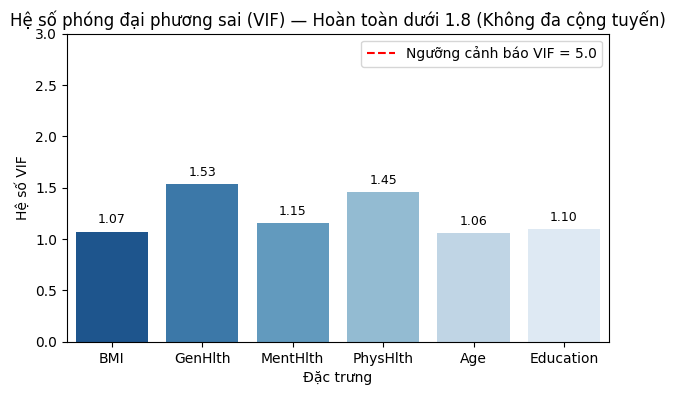

In [119]:
# Biểu đồ 12: Biểu đồ trực quan hóa hệ số VIF (Tất cả < 1.8)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=vif_data,
    x="Đặc trưng",
    y="Hệ số VIF",
    hue="Đặc trưng",
    palette="Blues_r",
    legend=False,
    ax=ax,
)
ax.axhline(5.0, color='red', linestyle='--', label='Ngưỡng cảnh báo VIF = 5.0')
ax.set_title("Hệ số phóng đại phương sai (VIF) — Hoàn toàn dưới 1.8 (Không đa cộng tuyến)")
ax.set_ylabel("Hệ số VIF")
ax.set_ylim(0, 3.0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.08), ha='center', fontsize=9)
ax.legend()
plt.show()


**Đánh giá kiểm định VIF:** Toàn bộ các hệ số VIF đều nằm dưới 1.8, thấp hơn rất nhiều so với ngưỡng an toàn chuẩn mực là 5.0. Kết quả này khẳng định không có sự phụ thuộc tuyến tính gây hại nào giữa các biến đầu vào.


# V. Thiết lập thử nghiệm tuần tự & Phân chia Train/Test

## 5.1. Phân chia Train/Test bằng StratifiedGroupKFold ngăn ngừa rò rỉ nhóm

Nhóm chia dữ liệu sạch của người **từ 60 tuổi trở lên (143.454 hồ sơ)** thành **80,00% Train (114.764 hồ sơ)** và **20,00% Test (28.690 hồ sơ)**, giữ hồ sơ trùng. Nhóm gom các hồ sơ có cùng 20 đặc trưng vào một nhóm bằng hàm băm, kể cả khi khác nhãn, rồi đưa các thành viên trong nhóm vào cùng một tập.

Nhóm lấy lần chia đầu tiên của `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` để tạo Train/Test với **Group Overlap = 0** tuyệt đối. Nhóm kiểm tra số hồ sơ, tỷ lệ nhãn và giao nhóm giữa hai tập trong bảng dưới. Nhóm dùng Test để đánh giá XGBoost sau khi chốt cấu hình và ngưỡng trên Train. Giới hạn của bước chọn biến bằng Pearson được nêu ở Phần VIII.

## 5.2. So sánh hai bộ đặc trưng qua 5-Fold CV trên Train

Nhóm so sánh `baseline_20` và `reduced16_plus4` bằng XGBoost trên cùng năm fold. Chỉ số so sánh là F1 lớp 1 ở ngưỡng 0,50 (xem [Mục 6.2](#62-so-sánh-hai-bộ-đặc-trưng)).

In [120]:
# Phân chia Train/Test bằng StratifiedGroupKFold ngăn ngừa rò rỉ nhóm
from sklearn.model_selection import StratifiedGroupKFold

df_clean['group_id'] = pd.util.hash_pandas_object(df_clean[FEATURES], index=False)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_idx, test_idx = next(sgkf.split(df_clean[FEATURES], df_clean[TARGET], df_clean['group_id']))
train_df = df_clean.iloc[train_idx].reset_index(drop=True)
test_df = df_clean.iloc[test_idx].reset_index(drop=True)

# Kiểm tra giao nhau giữa Train và Test
group_overlap = len(set(train_df['group_id']) & set(test_df['group_id']))
print(f"Xác nhận không rò rỉ dữ liệu: Số nhóm trùng lặp giữa Train và Test = {group_overlap}")
print(f"Tập Train: {len(train_df):,} dòng ({len(train_df)/len(df_clean)*100:.2f}%)")
print(f"Tập Test:  {len(test_df):,} dòng ({len(test_df)/len(df_clean)*100:.2f}%)")


Xác nhận không rò rỉ dữ liệu: Số nhóm trùng lặp giữa Train và Test = 0
Tập Train: 114,764 dòng (80.00%)
Tập Test:  28,690 dòng (20.00%)


In [121]:
# Bảng 28: Tổng hợp tỷ lệ phân chia tập Huấn luyện (Train) và Kiểm tra (Test)
split_summary = pd.DataFrame({
    "Tập dữ liệu": ["Tập Huấn luyện (Train)", "Tập Kiểm tra độc lập (Test)", "Toàn bộ tập sạch (df_clean)"],
    "Số lượng hồ sơ": [f"{len(train_df):,}", f"{len(test_df):,}", f"{len(df_clean):,}"],
    "Tỷ lệ phân chia (%)": [f"{len(train_df)/len(df_clean)*100:.2f}%", f"{len(test_df)/len(df_clean)*100:.2f}%", "100.00%"],
    "Số ca mắc (nhãn 1)": [f"{train_df['Diabetes_binary'].sum():,}", f"{test_df['Diabetes_binary'].sum():,}", f"{df_clean['Diabetes_binary'].sum():,}"],
    "Tỷ lệ nhãn 1 (%)": [f"{train_df['Diabetes_binary'].mean()*100:.2f}%", f"{test_df['Diabetes_binary'].mean()*100:.2f}%", f"{df_clean['Diabetes_binary'].mean()*100:.2f}%"],
    "Số nhóm trùng lặp giao nhau": [0, 0, 0]
})
display(split_summary)


,Tập dữ liệu,Số lượng hồ sơ,Tỷ lệ phân chia (%),Số ca mắc (nhãn 1),Tỷ lệ nhãn 1 (%),Số nhóm trùng lặp giao nhau
0,Tập Huấn luyện (Train),"114,764",80.00%,"25,162",21.92%,0
1,Tập Kiểm tra độc lập (Test),"28,690",20.00%,"6,290",21.92%,0
2,Toàn bộ tập sạch (df_clean),"143,454",100.00%,"31,452",21.92%,0


# VI. Chọn mô hình bằng kiểm định chéo

## 6.1. Chuẩn bị dữ liệu và fold

Nhóm dùng Train/Test và đối tượng `sgkf` từ Phần V. Vòng lặp đầu Phần VI giữ cách lấy năm fold theo nhóm và lưu các cặp chỉ số để dùng chung khi so sánh đặc trưng, dò siêu tham số và tạo dự đoán ngoài fold (OOF).

`baseline_20` gồm 20 biến gốc trong `FEATURES`. `reduced_16` loại AnyHealthcare, Age, Smoker và NoDocbcCost theo `dropped_4`. `reduced16_plus4` thêm bốn biến tương tác của Mục 4.5 vào `reduced_16`. Nhóm tạo các biến tương tác trên bản sao đầu vào của Train và Test bằng cùng công thức cố định. `FEATURES` và cách gom nhóm ở Phần V được giữ nguyên.

Phần mô hình dùng bốn biến loại theo |Pearson r| ở Bảng 23. Bảng 24 và phép kiểm tra VIF ở Phần IV của bản v3 mô tả bộ biến khảo sát trước đó.

In [122]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict, cross_val_score
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from xgboost import DMatrix, XGBClassifier

def add_interactions(df):
    return df.assign(
        BMI_HighBP=df['BMI'] * df['HighBP'],
        GenHlth_DiffWalk=(df['GenHlth'] - 1) * df['DiffWalk'],
        HighBP_HighChol=df['HighBP'] * df['HighChol'],
        GenHlth_PhysHlth=(df['GenHlth'] - 1) * df['PhysHlth'],
    )


baseline_20 = list(FEATURES)
dropped_4 = ['AnyHealthcare', 'Age', 'Smoker', 'NoDocbcCost']
interaction_features = ['BMI_HighBP', 'GenHlth_DiffWalk', 'HighBP_HighChol', 'GenHlth_PhysHlth']
reduced_16 = [c for c in baseline_20 if c not in dropped_4]
reduced16_plus4 = reduced_16 + interaction_features

X_tr = add_interactions(train_df[baseline_20])
X_te = add_interactions(test_df[baseline_20])
y_tr, y_te = train_df[TARGET].astype(int), test_df[TARGET].astype(int)
train_groups, test_groups = train_df['group_id'], test_df['group_id']

folds = []
fold_summary = []
for fold, (fit_idx, val_idx) in enumerate(sgkf.split(X_tr[baseline_20], train_df[TARGET], train_groups), start=1):
    folds.append((fit_idx, val_idx))
    overlap = len(set(train_groups.iloc[fit_idx]) & set(train_groups.iloc[val_idx]))
    fold_summary.append((fold, len(fit_idx), len(val_idx), y_tr.iloc[val_idx].mean(), overlap))

val_idx_all = np.concatenate([val_idx for _, val_idx in folds])
covered_once = np.array_equal(np.sort(val_idx_all), np.arange(len(X_tr)))
holdout_overlap = len(set(train_groups) & set(test_groups))
print(f'Validation phủ đúng một lần mỗi dòng Train = {covered_once}')
print(f'Số nhóm chung giữa Train và Test = {holdout_overlap}')
display(pd.DataFrame(fold_summary, columns=[
    'Fold', 'Số dòng fit', 'Số dòng validation', 'Tỉ lệ lớp 1 validation', 'Số nhóm chung',
]).round(4))
if not covered_once or holdout_overlap or any(row[-1] for row in fold_summary):
    raise ValueError('Kiểm tra độ phủ validation hoặc giao nhóm không đạt.')

Validation phủ đúng một lần mỗi dòng Train = True
Số nhóm chung giữa Train và Test = 0


,Fold,Số dòng fit,Số dòng validation,Tỉ lệ lớp 1 validation,Số nhóm chung
0,1,91810,22954,0.2193,0
1,2,91810,22954,0.2193,0
2,3,91812,22952,0.2192,0
3,4,91812,22952,0.2192,0
4,5,91812,22952,0.2192,0


## 6.2. So sánh hai bộ đặc trưng

Nhóm dùng F1 lớp 1 tại ngưỡng mặc định 0,50 trên cùng năm fold. Nhóm chọn bộ có F1 validation trung bình cao hơn. Khi chênh lệch nhỏ hơn một độ lệch chuẩn F1 giữa các fold của bộ dẫn đầu, hoặc khi hai bộ bằng điểm, nhóm chọn `baseline_20` vì bộ này chỉ cần các biến gốc.

**Kết quả.** `baseline_20` đạt F1 trung bình **0,4956** (độ lệch chuẩn 0,0058). `reduced16_plus4` đạt **0,4950** (độ lệch chuẩn 0,0034). Chọn `baseline_20`. Chênh lệch F1 (0.0005) nhỏ hơn độ lệch chuẩn của baseline_20 (0.0058). Ưu tiên bộ dùng các biến gốc.

In [123]:
n_pos = y_tr.sum()
n_neg = len(y_tr) - n_pos
xgb = XGBClassifier(
    tree_method='hist', scale_pos_weight=n_neg / n_pos, random_state=42, n_jobs=4,
)
feature_sets = {'baseline_20': baseline_20, 'reduced16_plus4': reduced16_plus4}
fold_scores = pd.DataFrame({
    name: cross_val_score(xgb, X_tr[columns], y_tr, cv=folds, scoring='f1', error_score='raise')
    for name, columns in feature_sets.items()
}, index=[f'Fold {i}' for i in range(1, len(folds) + 1)]).T
fold_scores['F1 trung bình'] = fold_scores.mean(axis=1)
fold_scores['Độ lệch chuẩn F1'] = fold_scores.iloc[:, :len(folds)].std(axis=1, ddof=0)
display(fold_scores.round(4))

mean_f1 = fold_scores['F1 trung bình']
leader = mean_f1.idxmax()
gap = abs(mean_f1['baseline_20'] - mean_f1['reduced16_plus4'])
leader_std = fold_scores.loc[leader, 'Độ lệch chuẩn F1']
if gap == 0:
    selected_name = 'baseline_20'
    reason = 'Hai bộ có cùng F1 trung bình. Ưu tiên bộ dùng các biến gốc.'
elif gap < leader_std:
    selected_name = 'baseline_20'
    reason = (f'Chênh lệch F1 ({gap:.4f}) nhỏ hơn độ lệch chuẩn của {leader} ({leader_std:.4f}). '
              'Ưu tiên bộ dùng các biến gốc.')
else:
    selected_name = leader
    reason = f'F1 trung bình cao hơn {gap:.4f}, đạt ít nhất một độ lệch chuẩn của bộ dẫn đầu ({leader_std:.4f}).'

selected_features = feature_sets[selected_name]
X_tr_model, X_te_model = X_tr[selected_features], X_te[selected_features]
print(f'Chọn {selected_name}. {reason}')

Chọn baseline_20. Chênh lệch F1 (0.0005) nhỏ hơn độ lệch chuẩn của baseline_20 (0.0058). Ưu tiên bộ dùng các biến gốc.


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,F1 trung bình,Độ lệch chuẩn F1
baseline_20,0.4975,0.5023,0.4911,0.5001,0.4868,0.4956,0.0058
reduced16_plus4,0.4936,0.4990,0.4924,0.4991,0.4909,0.4950,0.0034


## 6.3. Dò siêu tham số và kiểm tra overfitting

RandomizedSearchCV thử 20 cấu hình trên cùng năm fold và chọn theo F1 validation trung bình. Độ sâu tối đa, trọng số tối thiểu ở nút con và regularization L2 kiểm soát độ phức tạp của cây. Lấy mẫu hàng và cột cũng giúp hạn chế việc mô hình bám quá sát Train. Chênh lệch F1 giữa các phần fit và validation cho thấy mức suy giảm khi dự đoán trên dữ liệu ngoài phần fit.

**Kết quả.** F1 trung bình của cấu hình tốt nhất là 0,5079 trên fit và 0,5053 trên validation, chênh 0,0026. Khoảng cách này cho thấy ít dấu hiệu overfitting qua các fold đã dùng.

In [124]:
param_grid = {
    'n_estimators': [100, 200, 300, 400],
    'learning_rate': [0.03, 0.05, 0.10, 0.15],
    'max_depth': [2, 3, 4, 5, 6],
    'min_child_weight': [1, 5, 10, 20],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0],
    'reg_lambda': [1, 3, 10, 20],
}
search = RandomizedSearchCV(
    xgb, param_grid, n_iter=20, scoring='f1', cv=folds,
    return_train_score=True, random_state=42, error_score='raise',
)
search.fit(X_tr_model, y_tr)
best_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_)
best = results.loc[search.best_index_]
fit_f1, val_f1 = best['mean_train_score'], best['mean_test_score']
print(f'F1 fit = {fit_f1:.4f} | F1 validation = {val_f1:.4f} | Chênh lệch = {fit_f1 - val_f1:+.4f}')
print(f'F1 giảm {(fit_f1 - val_f1) * 100:.2f} điểm phần trăm từ fit sang validation của cấu hình được chọn.')
top_cols = [f'param_{name}' for name in param_grid]
top_5 = results.sort_values('rank_test_score').head(5)
display(top_5[['rank_test_score', *top_cols, 'mean_train_score', 'mean_test_score', 'std_test_score']]
        .rename(columns={'rank_test_score': 'Hạng', 'mean_train_score': 'F1 fit',
                         'mean_test_score': 'F1 validation', 'std_test_score': 'Độ lệch chuẩn validation',
                         **{col: col.removeprefix('param_') for col in top_cols}})
        .round(4))

F1 fit = 0.5079 | F1 validation = 0.5053 | Chênh lệch = +0.0026
F1 giảm 0.26 điểm phần trăm từ fit sang validation của cấu hình được chọn.


,Hạng,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,F1 fit,F1 validation,Độ lệch chuẩn validation
15,1,200,0.15,2,1,1.00,1.0,20,0.5079,0.5053,0.0045
13,2,100,0.05,5,20,1.00,0.7,3,0.5109,0.5051,0.0041
7,3,300,0.03,4,5,0.85,0.7,20,0.5096,0.5050,0.0043
12,4,200,0.03,5,5,0.70,1.0,10,0.5121,0.5049,0.0041
14,5,100,0.03,6,1,0.85,0.7,1,0.5137,0.5047,0.0036


## 6.4. Chọn ngưỡng trên Train

Mỗi xác suất OOF đến từ mô hình fit trên bốn fold còn lại. Nhóm chọn ngưỡng có F1 lớp 1 cao nhất trong khoảng 0,10–0,90 với bước 0,01. Nếu nhiều ngưỡng cùng điểm, nhóm lấy ngưỡng thấp nhất. Điểm OOF ở đây phục vụ chọn ngưỡng vì siêu tham số cũng đã được chọn trên Train.

**Kết quả.** Ngưỡng 0,55 cho F1 OOF cao nhất (0,5088). Khi đổi từ ngưỡng 0,50 sang ngưỡng chọn, Precision OOF đổi từ 38,79% thành 41,60% và Recall từ 72,44% thành 65,50%.

In [125]:
oof_prob = cross_val_predict(best_model, X_tr_model, y_tr, cv=folds, method='predict_proba')[:, 1]
thresholds = np.arange(10, 91) / 100
threshold_scores = np.array([
    f1_score(y_tr, oof_prob >= threshold, zero_division=0) for threshold in thresholds
])
best_threshold_idx = threshold_scores.argmax()
threshold = thresholds[best_threshold_idx]
print(f'Ngưỡng chọn = {threshold:.2f} | F1 OOF = {threshold_scores[best_threshold_idx]:.4f}')

oof_metrics = pd.DataFrame([
    {
        'Ngưỡng': cutoff,
        'Precision lớp 1': precision_score(y_tr, oof_prob >= cutoff, zero_division=0),
        'Recall lớp 1': recall_score(y_tr, oof_prob >= cutoff, zero_division=0),
    }
    for cutoff in (0.50, threshold)
], index=['Ngưỡng mặc định', 'Ngưỡng chọn'])
display(oof_metrics.round(4))

Ngưỡng chọn = 0.55 | F1 OOF = 0.5088


,Ngưỡng,Precision lớp 1,Recall lớp 1
Ngưỡng mặc định,0.50,0.3879,0.7244
Ngưỡng chọn,0.55,0.4160,0.6550


# VII. Đánh giá cuối trên Test

## 7.1. Chỉ số, ma trận nhầm lẫn và ROC

RandomizedSearchCV đã fit lại cấu hình tốt nhất trên toàn bộ Train. Nhóm áp dụng ngưỡng OOF cho Test để tính các chỉ số phân loại. ROC-AUC dùng trực tiếp xác suất dự đoán.

**Kết quả.** Ở ngưỡng 0,55, XGBoost đạt F1 lớp 1 **0,5097**, Precision 41,73% và Recall 65,45% trên Test. ROC-AUC là **0,7717**.

,Test
Ngưỡng,0.5500
Accuracy,0.7239
Precision lớp 1,0.4173
Recall lớp 1,0.6545
F1 lớp 1,0.5097
ROC-AUC,0.7717


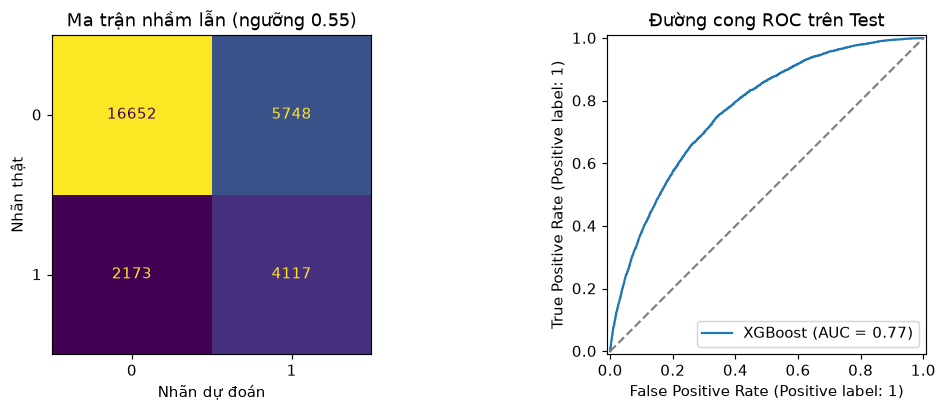

In [126]:
test_prob = best_model.predict_proba(X_te_model)[:, 1]
test_pred = (test_prob >= threshold).astype(int)
test_f1 = f1_score(y_te, test_pred, zero_division=0)
test_auc = roc_auc_score(y_te, test_prob)
display(pd.Series({
    'Ngưỡng': threshold, 'Accuracy': accuracy_score(y_te, test_pred),
    'Precision lớp 1': precision_score(y_te, test_pred, zero_division=0),
    'Recall lớp 1': recall_score(y_te, test_pred, zero_division=0),
    'F1 lớp 1': test_f1, 'ROC-AUC': test_auc,
}, name='Test').round(4).to_frame())

cm = confusion_matrix(y_te, test_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(ax=axes[0], colorbar=False, values_format='d')
axes[0].set(title=f'Ma trận nhầm lẫn (ngưỡng {threshold:.2f})', xlabel='Nhãn dự đoán', ylabel='Nhãn thật')
RocCurveDisplay.from_predictions(y_te, test_prob, ax=axes[1], name='XGBoost')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set_title('Đường cong ROC trên Test')
fig.tight_layout()
plt.show()

## 7.2. Phân tích lỗi

Dương tính giả (FP) là hồ sơ nhãn 0 bị dự đoán thành lớp 1. Âm tính giả (FN) là hồ sơ nhãn 1 bị bỏ sót. Nhóm báo cáo tỉ lệ lỗi trên từng lớp thật và đối chiếu theo nhóm tuổi để mô tả lỗi của mô hình trên Test.

**Kết quả.** Mô hình báo nhầm 5.748 hồ sơ lớp 0 (25,66%) và bỏ sót 2.173 hồ sơ lớp 1 (34,55%). Tỉ lệ báo nhầm cao nhất ở mã nhóm tuổi 12 (32,61%). Tỉ lệ bỏ sót cao nhất ở mã nhóm tuổi 13 (44,71%).

In [127]:
print(f'FP = {fp:,}/{tn + fp:,} hồ sơ lớp 0 ({fp / (tn + fp):.2%}).')
print(f'FN = {fn:,}/{tp + fn:,} hồ sơ lớp 1 ({fn / (tp + fn):.2%}).')

error_summary = []
for age, rows in X_te.groupby('Age').groups.items():
    a_tn, a_fp, a_fn, a_tp = confusion_matrix(y_te.loc[rows], test_pred[rows], labels=[0, 1]).ravel()
    error_summary.append((age, len(rows), a_fp, a_fn,
                          a_fp / (a_tn + a_fp) if a_tn + a_fp else np.nan,
                          a_fn / (a_tp + a_fn) if a_tp + a_fn else np.nan))
display(pd.DataFrame(error_summary, columns=[
    'Mã nhóm tuổi', 'Số hồ sơ', 'FP', 'FN', 'FP / số lớp 0', 'FN / số lớp 1',
]).round(4))

FP = 5,748/22,400 hồ sơ lớp 0 (25.66%).
FN = 2,173/6,290 hồ sơ lớp 1 (34.55%).


,Mã nhóm tuổi,Số hồ sơ,FP,FN,FP / số lớp 0,FN / số lớp 1
0,9,7451,1253,480,0.2085,0.3329
1,10,7310,1415,507,0.2493,0.3103
2,11,5533,1226,433,0.2940,0.3177
3,12,3930,977,343,0.3261,0.3672
4,13,4466,877,410,0.2471,0.4471


## 7.3. Feature Importance

Gain là mức giảm loss trung bình từ các lần chia dùng một biến. Nhóm đưa cả những biến cây chưa dùng vào bảng với gain bằng 0.

**Kết quả.** Bốn biến dẫn đầu theo gain lần lượt là `HighBP` (1693,2655), `GenHlth` (580,9662), `BMI` (368,2549), `HighChol` (294,1069). Gain đo mức giảm loss tại các lần chia và không cho biết chiều đóng góp hay quan hệ nhân quả.

,Gain trung bình
HighBP,1693.2655
GenHlth,580.9662
BMI,368.2549
HighChol,294.1069


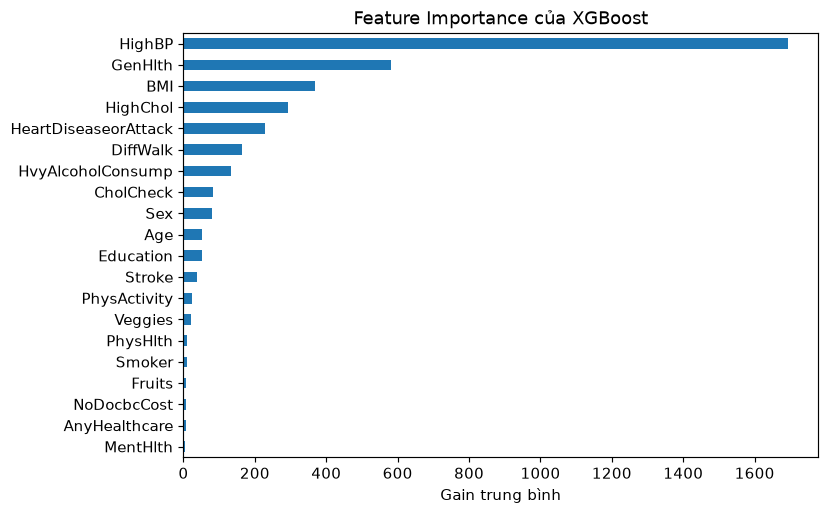

In [128]:
booster = best_model.get_booster()
gain = pd.Series(booster.get_score(importance_type='gain'), dtype=float)
gain = gain.reindex(selected_features, fill_value=0).sort_values()
display(gain.nlargest(4).round(4).rename('Gain trung bình').to_frame())
ax = gain.plot.barh(figsize=(8, 5), title='Feature Importance của XGBoost')
ax.set_xlabel('Gain trung bình')
plt.tight_layout()
plt.show()

## 7.4. SHAP

Nhóm dùng TreeSHAP tích hợp trong XGBoost trên tối đa 1.000 hồ sơ Test lấy mẫu với seed cố định. Trung bình |SHAP| xếp hạng mức đóng góp trên mẫu. Với từng ví dụ FP và FN, dấu dương đẩy điểm log-odds về lớp 1 và dấu âm kéo điểm về lớp 0. Nhóm minh họa lỗi có điểm dự đoán xa ngưỡng nhất trong mỗi loại lỗi.

**Kết quả.** Trên 1.000 hồ sơ Test lấy mẫu, `GenHlth` có trung bình |SHAP| cao nhất (0,4586 log-odds). Gain đo mức giảm loss trung bình mỗi lần chia, còn |SHAP| đo độ lớn đóng góp trung bình trên từng hồ sơ. Ở ca FP (điểm lớp 1 0,9345), `BMI` làm tăng log-odds lớp 1 mạnh nhất (SHAP 0,8437). Ở ca FN (điểm lớp 1 0,0187), `BMI` làm giảm log-odds lớp 1 mạnh nhất (SHAP -1,1758). Hai ca minh họa chỉ phản ánh hai hồ sơ được chọn.

FP: BMI, SHAP = +0.8437, điểm lớp 1 = 0.9345
FN: BMI, SHAP = -1.1758, điểm lớp 1 = 0.0187


,Trung bình |SHAP|
GenHlth,0.4586


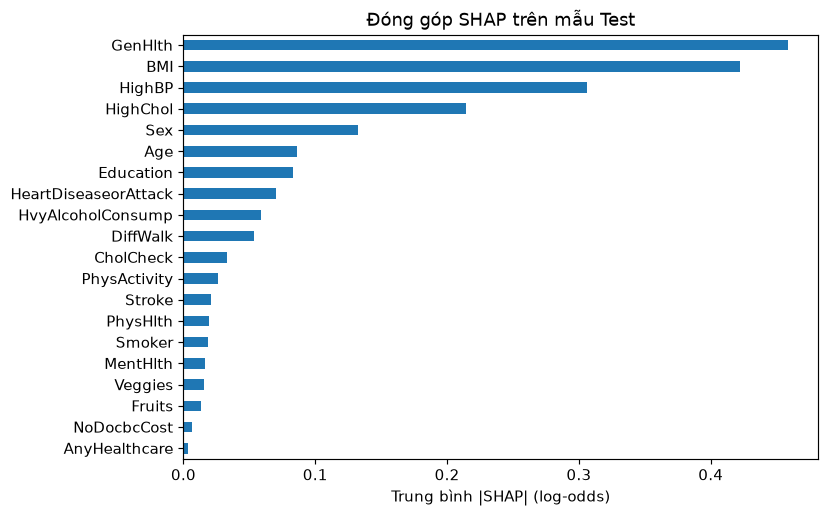

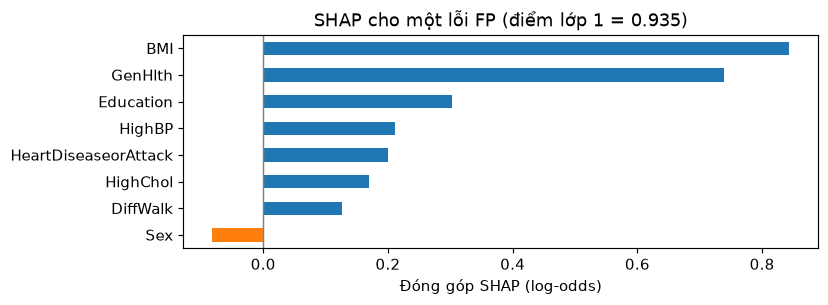

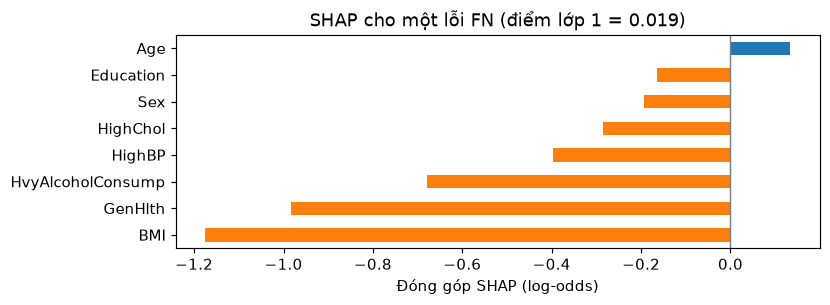

In [129]:
X_shap = X_te_model.sample(n=min(1000, len(X_te_model)), random_state=42)
shap_values = booster.predict(DMatrix(X_shap), pred_contribs=True)[:, :-1]
mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=selected_features).sort_values()
display(mean_abs_shap.nlargest(1).round(4).rename('Trung bình |SHAP|').to_frame())
ax = mean_abs_shap.plot.barh(figsize=(8, 5), title='Đóng góp SHAP trên mẫu Test')
ax.set_xlabel('Trung bình |SHAP| (log-odds)')
plt.tight_layout()
plt.show()

local_shap_examples = {}
for error_name, mask in [('FP', (y_te == 0) & (test_pred == 1)), ('FN', (y_te == 1) & (test_pred == 0))]:
    positions = np.flatnonzero(mask)
    if not positions.size:
        continue
    pos = positions[np.abs(test_prob[positions] - threshold).argmax()]
    contributions = booster.predict(DMatrix(X_te_model.iloc[[pos]]), pred_contribs=True)[0]
    local_shap = pd.Series(contributions[:-1], index=selected_features)
    main_feature = local_shap.abs().idxmax()
    local_shap_examples[error_name] = (main_feature, float(local_shap[main_feature]), float(test_prob[pos]))
    print(f'{error_name}: {main_feature}, SHAP = {local_shap[main_feature]:+.4f}, điểm lớp 1 = {test_prob[pos]:.4f}')
    top = local_shap.loc[local_shap.abs().nlargest(8).index].sort_values()
    ax = top.plot.barh(figsize=(8, 3), color=np.where(top >= 0, 'tab:blue', 'tab:orange'),
                      title=f'SHAP cho một lỗi {error_name} (điểm lớp 1 = {test_prob[pos]:.3f})')
    ax.axvline(0, color='gray', linewidth=1)
    ax.set_xlabel('Đóng góp SHAP (log-odds)')
    plt.tight_layout()
    plt.show()

# VIII. Kết luận và giới hạn

**Kết quả.** `baseline_20` đạt F1 CV 0,4956, còn `reduced16_plus4` đạt 0,4950. Phương án thay bốn biến gốc bằng bốn biến tương tác chưa cải thiện F1 CV. Nhóm chọn `baseline_20` cho XGBoost.

**Kết quả.** Ở ngưỡng 0,55, mô hình đạt F1 lớp 1 0,5097 và ROC-AUC 0,7717 trên Test. Tỉ lệ FP là 25,66% trên lớp 0 và tỉ lệ FN là 34,55% trên lớp 1. Nhóm tuổi từ 80 tuổi trở lên (mã 13) có tỉ lệ bỏ sót cao nhất (44,71%). Mã nhóm tuổi 10 có số FN cao nhất (507 hồ sơ).

Nhóm chọn bốn biến loại khỏi `reduced_16` bằng tương quan Pearson với nhãn trên toàn bộ dữ liệu sạch, gồm cả Test. Vì vậy, dữ liệu Test đã tham gia vào quyết định thiết kế bộ đặc trưng đem so sánh. Nhãn nghiên cứu là thông tin tự khai gộp tiền tiểu đường và tiểu đường ở người từ 60 tuổi trở lên.

## Hướng phát triển

- Xác thực ngoài trên dữ liệu của năm khác hoặc quần thể khác.
- Chọn biến trong phần fit của từng fold CV để giữ validation và Test ngoài bước chọn biến.
- Thử thêm biến lâm sàng hoặc hiệu chỉnh xác suất dự đoán.

In [130]:
print(f'XGBoost dùng {selected_name}, ngưỡng {threshold:.2f}.')
print(f'Test có F1 lớp 1 = {test_f1:.4f}, ROC-AUC = {test_auc:.4f}, {fp:,} báo nhầm và {fn:,} bỏ sót.')
print(f'Biến đứng đầu theo gain: {gain.idxmax()}. Theo trung bình |SHAP|: {mean_abs_shap.idxmax()}.')

XGBoost dùng baseline_20, ngưỡng 0.55.
Test có F1 lớp 1 = 0.5097, ROC-AUC = 0.7717, 5,748 báo nhầm và 2,173 bỏ sót.
Biến đứng đầu theo gain: HighBP. Theo trung bình |SHAP|: GenHlth.


## Tài liệu tham khảo

- [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html) và [BRFSS2015 Codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf): nguồn dữ liệu, nội dung câu hỏi, mã phản hồi và nhánh câu hỏi.
- [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) và [notebook Alex Teboul](https://www.kaggle.com/code/alexteboul/diabetes-health-indicators-dataset-notebook): căn cứ kế thừa bộ biến đặc trưng và phần lớn quy trình xử lý ban đầu. Nhóm chọn người từ 60 tuổi trở lên trong báo cáo này, loại hồ sơ chỉ tiểu đường khi mang thai, và gộp tiền tiểu đường/tiểu đường thành lớp 1 theo định nghĩa nghiên cứu.
- Các nghiên cứu và tài liệu y tế chuyên ngành dịch tễ học. Nhóm xem xét khác biệt về quần thể, năm khảo sát, nhãn và cách đo khi sử dụng kết quả tham khảo.